# Band-stealthy temporal disorder

**Suppression of disorder-induced parametric amplification in time-varying media**

Random temporal modulation of a dielectric makes the energy of a wave grow (Sharabi, Lustig
and Segev, 2021), and designed correlations in the modulation sequence change how the wave
scatters (Kim, Lee, Yu and Park, 2023). In the spatial Anderson problem, disorder whose
spectrum vanishes on a band of wavevectors leaves the corresponding states effectively
delocalized (Vanoni et al., 2026). The temporal counterpart studied here removes a band of
the modulation spectrum and asks how completely this suppresses the amplification of the
modes that couple to it, what it costs the other modes, and what limits the suppression.

This notebook is the complete computational record of the study. Running its cells in order
regenerates every intermediate data set in `results/`, every figure in `figures/`, and the
table of final numbers in Section 16. Nothing is read from disk that the notebook has not
written itself. On a two-core machine the full run takes about twenty minutes.

Random numbers come from generators seeded by hashing descriptive tags with SHA-256
(`src/ensembles.py`), so each ensemble is fixed by its name alone and a rerun reproduces
all numbers bit for bit on the same software stack.

**Contents**

1. Physical model
2. Growth rates and how they are measured
3. Band-stealthy modulation
4. Residual amplification inside the removed band
5. Validation of the numerical and analytical tools
6. Production ensembles
7. Finite-horizon crossover and estimator checks
8. Protection factor
9. Depth scaling and the residual theory
10. Redistribution cost for unprotected modes
11. Long-horizon rates
12. Band placement and constrained fraction
13. Band edges and usable bandwidth
14. Realizability
15. Analysis choices and systematic uncertainty
16. Summary of results

The reusable code lives in `src/`: `model.py` (exact slab propagation and exact reference
rates), `ensembles.py` (modulation sequences), `simulate.py` (ensemble runs),
`theory.py` (diffusion-limit crossover and residual theory), `dispersive.py` (Lorentz
medium), `figures.py` (figure style and layout checks) and `records.py` (result files that
do not change between runs).

In [1]:
%matplotlib inline
import time
from pathlib import Path

import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

from src import dispersive, model, records, simulate, theory
from src import ensembles as ens
from src import figures as fg

fg.setup()
RESULTS, FIGURES = Path("results"), Path("figures")
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
summary = {}          # final numbers, written to results/summary.json in Section 16
clock = time.time()

### Study parameters

All parameters of the study are set in the next cell. Time is measured in units of the slab
duration $\tau$ and frequencies in units of $1/\tau$. The mode frequencies $\omega$ form a
uniform grid; the modulation spectrum is removed on the band $\Omega=[1.0,1.6]$ of
modulation frequencies $\varpi$, which protects the modes whose parametric resonance
$\varpi=2\omega$ falls inside it, the window $\Omega/2=[0.5,0.8]$. The modulation depth
$m_0$ is the standard deviation of the slab values $\mu_j$.

In [2]:
OMEGA = np.linspace(0.20, 1.50, 53)           # mode frequencies, step 0.025
BAND = (1.0, 1.6)                             # removed band of modulation frequencies
WINDOW = (BAND[0] / 2, BAND[1] / 2)           # protected modes: 2 omega inside BAND
DEPTHS = np.array([0.02, 0.05, 0.075, 0.10, 0.15, 0.20])
M0 = 0.05                                     # primary modulation depth
N = 4096                                      # slabs per realization (primary horizon)
M = 400                                       # realizations per frequency and ensemble
FIT = (0.2, 0.8)                              # fit window, fractions of the horizon
FIT_WINDOWS = [(0.2, 0.8), (0.1, 0.9), (0.3, 0.7), (0.5, 1.0)]
HORIZONS = [1024, 4096, 8192, 16384]
FAMILIES = 12                                 # independent seed families at M0
R_STAR = 10.0                                 # protection threshold for the usable band

BINS = ens.band_bins(N, BAND)
NC = len(BINS)
KAPPA2 = ens.kappa2(N, NC)
INNER = (OMEGA > WINDOW[0] + 1e-9) & (OMEGA < WINDOW[1] - 1e-9)   # interior of the window
OUTER = (OMEGA < 0.45 - 1e-9) | (OMEGA > 0.85 + 1e-9)             # well clear of the window
I_PRIMARY = int(np.argmin(np.abs(DEPTHS - M0)))
I_CENTRE = int(np.argmin(np.abs(OMEGA - 0.65)))

print(f"constrained bins N_c = {NC}, first/last bin frequency = "
      f"{2*np.pi*BINS[0]/N:.5f} / {2*np.pi*BINS[-1]/N:.5f}")
print(f"constrained fraction chi = N_c/(N/2) = {NC/(N/2):.4f}, kappa^2 = {KAPPA2:.6f}")
print(f"interior window modes: {INNER.sum()}, out-of-window modes: {OUTER.sum()}")
summary["setup"] = {"N": N, "M": M, "n_omega": len(OMEGA), "band": BAND, "window": WINDOW,
                    "Nc": int(NC), "chi": NC / (N / 2), "kappa2": KAPPA2,
                    "depths": DEPTHS.tolist(), "m0_primary": M0, "horizons": HORIZONS,
                    "families": FAMILIES, "n_inner": int(INNER.sum()),
                    "n_outer": int(OUTER.sum())}

constrained bins N_c = 392, first/last bin frequency = 1.00016 / 1.59994
constrained fraction chi = N_c/(N/2) = 0.1914, kappa^2 = 1.236786
interior window modes: 11, out-of-window modes: 36


## 1. Physical model

### 1.1 Wave equation for a time-varying medium

A spatially uniform, lossless, non-magnetic dielectric whose relative permittivity
$\varepsilon_r(t)$ changes in time conserves the wavevector of a plane wave, so each
wavevector $k$ evolves on its own. For a transverse wave $\propto e^{ikx}$ with
$D=\varepsilon_0\varepsilon_r E$ and $B=\mu_0H$, Faraday's and Ampère's laws read
$\dot B=-ikE$ and $\dot D=-ikB/\mu_0$. Eliminating $B$ gives

$$\ddot D+\frac{c^2k^2}{\varepsilon_r(t)}\,D=0 .$$

At an abrupt change of $\varepsilon_r$ the fields $D$ and $B$ remain continuous
(Morgenthaler, 1958), and since $\dot D\propto B$ the pair $(D,\dot D)$ is continuous.

Define the reference permittivity $\bar\varepsilon$ through $1/\bar\varepsilon=\langle
1/\varepsilon_r\rangle$ and the mode frequency $\omega=ck/\sqrt{\bar\varepsilon}$. The wave
equation becomes Hill's equation

$$\ddot D+\omega^2\,[1+\mu(t)]\,D=0,\qquad \mu(t)=\frac{\bar\varepsilon}{\varepsilon_r(t)}-1,
\qquad \langle\mu\rangle=0. \tag{1}$$

The modulation is a staircase of slabs, $\mu(t)=\mu_j$ for $j\tau\le t<(j+1)\tau$. The
variable that enters the wave equation is $\mu$, not the permittivity modulation
$\delta=\varepsilon_r/\bar\varepsilon-1$; the difference matters in Section 14.1.

The next cell checks the elimination symbolically, together with the slab solution and the
amplitude equations used below.

In [3]:
t = sp.symbols("t", real=True)
k, c, eps0, mu0 = sp.symbols("k c epsilon_0 mu_0", positive=True)
eps_r = sp.Function("epsilon_r", positive=True)(t)
D, B = sp.Function("D")(t), sp.Function("B")(t)
E_field = D / (eps0 * eps_r)
dB = -sp.I * k * E_field                     # Faraday
dD = -sp.I * k * B / mu0                     # Ampere
D2 = sp.diff(dD, t).subs(sp.Derivative(B, t), dB)
hill = sp.simplify((D2 + c**2 * k**2 / eps_r * D).subs(c, 1 / sp.sqrt(eps0 * mu0)))
print("Maxwell -> Hill residual:", hill)

w, D0, Dd0 = sp.symbols("w D_0 Ddot_0", positive=True)
D_slab = D0 * sp.cos(w * t) + Dd0 * sp.sin(w * t) / w
M_slab = sp.Matrix([[sp.cos(w), sp.sin(w) / w], [-w * sp.sin(w), sp.cos(w)]])
print("slab solution residual:", sp.simplify(sp.diff(D_slab, t, 2) + w**2 * D_slab),
      "| det M =", sp.simplify(M_slab.det()))

om, mu_s = sp.symbols("omega mu", real=True)
a, b = sp.Function("a")(t), sp.Function("b")(t)
a_dot = -sp.I * om * mu_s / 2 * (a + b * sp.exp(2 * sp.I * om * t))
b_dot = sp.I * om * mu_s / 2 * (b + a * sp.exp(-2 * sp.I * om * t))
D_ab = a * sp.exp(-sp.I * om * t) + b * sp.exp(sp.I * om * t)
Ddot_ab = -sp.I * om * (a * sp.exp(-sp.I * om * t) - b * sp.exp(sp.I * om * t))
gauge = sp.simplify(sp.expand(a_dot * sp.exp(-sp.I * om * t) + b_dot * sp.exp(sp.I * om * t)))
Dddot = sp.diff(Ddot_ab, t).subs({sp.Derivative(a, t): a_dot, sp.Derivative(b, t): b_dot})
eom = sp.simplify(sp.expand(Dddot + om**2 * (1 + mu_s) * D_ab))
flux = sp.simplify(sp.expand(a_dot * sp.conjugate(a) + a * sp.conjugate(a_dot)
                             - b_dot * sp.conjugate(b) - b * sp.conjugate(b_dot)))
energy = sp.simplify(sp.expand(om**2 * D_ab * sp.conjugate(D_ab) + Ddot_ab * sp.conjugate(Ddot_ab)
                               - 2 * om**2 * (a * sp.conjugate(a) + b * sp.conjugate(b))))
print("gauge:", gauge, "| equation of motion:", eom, "| d(|a|^2-|b|^2)/dt:", flux,
      "| E - 2 w^2 (|a|^2+|b|^2):", energy)
assert hill == 0 and gauge == 0 and eom == 0 and flux == 0 and energy == 0

Maxwell -> Hill residual: 0
slab solution residual: 0 | det M = 1
gauge: 0 | equation of motion: 0 | d(|a|^2-|b|^2)/dt: 0 | E - 2 w^2 (|a|^2+|b|^2): 0


### 1.2 Exact slab propagator

Inside slab $j$ the squared frequency $w_j^2=\omega^2(1+\mu_j)$ is constant, and

$$\begin{pmatrix}D\\ \dot D\end{pmatrix}_{j+1}=\mathsf M_j\begin{pmatrix}D\\ \dot D\end{pmatrix}_{j},
\qquad
\mathsf M_j=\begin{pmatrix}\cos w_j & w_j^{-1}\sin w_j\\ -w_j\sin w_j & \cos w_j\end{pmatrix}, \tag{2}$$

with the hyperbolic continuation when $w_j^2<0$ (only in the far tail $\mu_j<-1$ of the
Gaussian ensembles). Each $\mathsf M_j$ is real with unit determinant, so the product of
slab matrices lies in $SL(2,\mathbb R)$, its two Lyapunov exponents sum to zero, and the top
exponent obeys $\lambda_1\ge0$. `model.propagate` applies Eq. (2) slab by slab; there is no
time-stepping error.

### 1.3 Amplitudes and energy

Writing $D=a\,e^{-i\omega t}+b\,e^{i\omega t}$ with the gauge condition
$\dot a\,e^{-i\omega t}+\dot b\,e^{i\omega t}=0$ turns Eq. (1) into

$$\dot a=-\frac{i\omega\mu}{2}\left(a+b\,e^{2i\omega t}\right),\qquad
\dot b=\frac{i\omega\mu}{2}\left(b+a\,e^{-2i\omega t}\right). \tag{3}$$

The combination $|a|^2-|b|^2$ is conserved. A forward launch, $a(0)=1$ and $b(0)=0$, keeps
$|a|^2=1+|b|^2$, and with the backscattered intensity $\rho=|b|^2$ the energy measure

$$E=\omega^2|D|^2+|\dot D|^2=2\omega^2\left(|a|^2+|b|^2\right)=2\omega^2(1+2\rho) \tag{4}$$

grows only by transfer into the time-reversed wave. $E$ differs from the instantaneous
electromagnetic energy, which is proportional to $\omega^2(1+\mu)|D|^2+|\dot D|^2$, by a
factor $1+O(m_0)$ that does not affect growth rates.

## 2. Growth rates and how they are measured

Two rates characterize the amplification of an ensemble:

$$\Gamma_2=\lim_{t\to\infty}\frac1t\ln\langle E(t)\rangle,\qquad
\Gamma_{\rm typ}=\lim_{t\to\infty}\frac1t\,\langle\ln E(t)\rangle=2\lambda_1 . \tag{5}$$

$\Gamma_2$ describes the ensemble-averaged energy and $\Gamma_{\rm typ}$ a typical
realization.

**Leading order.** Integrating Eq. (3) once with $a\simeq1$ gives
$\langle\rho(t)\rangle\simeq\nu t$ with

$$\nu=\frac{\omega^2}{4}\,S_\mu(2\omega),\qquad
S_\mu(\varpi)=\int_{-\infty}^{\infty}\langle\mu(t+s)\,\mu(t)\rangle\,e^{i\varpi s}\,ds . \tag{6}$$

Only the spectral component of the modulation at twice the mode frequency drives the growth:
this is parametric resonance. For independent slabs of variance $m_0^2$ the staircase has
$S_\mu(\varpi)=m_0^2\,\mathrm{sinc}^2(\varpi/2)$ with $\mathrm{sinc}\,x=\sin x/x$, and the
leading-order (Born) rate is $\Gamma_2=2\nu=\tfrac12 m_0^2\sin^2\omega$.

**Exact rate for independent slabs.** Because $\mathsf M_j$ is real,
$z_{j+1}\otimes z_{j+1}^{*}=(\mathsf M_j\otimes\mathsf M_j)(z_j\otimes z_j^{*})$ for the state
$z=(D,\dot D)$, and for independent slabs the average evolves with
$\mathbb E[\mathsf M\otimes\mathsf M]$. Therefore

$$\Gamma_2=\ln\max\left|\operatorname{eig}\,\mathbb E\left[\mathsf M\otimes\mathsf M\right]\right| \tag{7}$$

at any depth. `model.kronecker_rate` evaluates the Gaussian average with 41-node
Gauss-Hermite quadrature. Eq. (7) is the white-noise reference in every protection factor.

**Diffusion limit.** For weak modulation the phase of $a^*b$ randomizes on a time short
compared with $1/\nu$, and the backscattered intensity obeys the Itô equation

$$d\rho=(1+2\rho)\,ds+\sqrt{2\rho(1+\rho)}\,dW,\qquad s=\nu t, \tag{8}$$

the single-channel form of the Dorokhov-Mello-Pereyra-Kumar equation (Beenakker, 1997). In
the variable $r$ defined by $\cosh r=1+2\rho$ its generator is $\partial_r^2+\coth r\,\partial_r$,
the radial Laplacian of the hyperbolic plane. Applying the generator to $1+2\rho$ and to
$\ln(1+\rho)$ gives two exact identities, $\langle1+2\rho\rangle=e^{2s}$ and
$\langle\ln(1+\rho)\rangle=s$, hence

$$\Gamma_2=2\nu,\qquad \Gamma_{\rm typ}=\nu,\qquad \Gamma_2=2\,\Gamma_{\rm typ}. \tag{9}$$

The last relation is the temporal counterpart of single-parameter scaling in one-dimensional
localization (Anderson, Thouless, Abrahams and Fisher, 1980).

**Forward launch at a finite horizon.** For the forward launch
$\ln E=\ln2\omega^2+\ln(1+2\rho)$. At early times $\ln(1+2\rho)\simeq2\rho$ grows at $2\nu$,
at late times it grows at $\nu$. A least-squares slope fitted over $[0.2N,0.8N]$ is therefore
$\Gamma_{\rm typ}\,g_f(x)$ with $x=\Gamma_{\rm typ}N$, where $g_f$ falls from 2 at small
$x$ to 1 at large $x$. The function $g_f$ follows from the closed-form heat kernel of the
hyperbolic plane (McKean; see Grigor'yan and Noguchi, 1998),

$$p_s(r)=\frac{\sqrt2\,e^{-s/4}}{(4\pi s)^{3/2}}\int_r^\infty
\frac{q\,e^{-q^2/4s}}{\sqrt{\cosh q-\cosh r}}\,dq , \tag{10}$$

with radial measure $2\pi\sinh r\,dr$. `theory.g_forward` averages $\ln(1+2\rho)$ with this
density on the same checkpoints and fit window as the simulations.

**Standing-wave launch.** The launch $D(0)=1$, $\dot D(0)=0$ is the real part of the
forward solution, with $E_s=\omega^2|a+b^*|^2=\omega^2\,|\sqrt{1+\rho}+\sqrt{\rho}\,e^{i\theta}|^2$.
For a uniformly distributed phase $\theta$, Jensen's formula gives
$\langle\ln E_s\rangle=\ln\omega^2+\langle\ln(1+\rho)\rangle=\ln\omega^2+\nu t$ exactly: the
standing-wave slope equals $\Gamma_{\rm typ}$ at every horizon. The QR estimator of
$\lambda_1$ propagates this launch in the variables $(\omega D,\dot D)$, in which free
evolution is a rotation, so it is unbiased at every horizon and returns exactly zero for a
constant medium (`model.lyapunov_rate`). Both launches come from one propagation, because
the slab matrices are real.

**Like-for-like protection factor.** Raw typical slopes of two ensembles measured at
different $x$ are not comparable, because each carries its own crossover factor. Every
forward-launch slope is therefore converted into a mean-energy rate
$\hat\Gamma_2=2\hat x/N$, where $\hat x$ solves $\hat x\,g_f(\hat x)=N\times\text{slope}$, and
the protection factor is

$$R(\omega)=\frac{\Gamma_{2,W}(\omega)}{\hat\Gamma_{2,S}(\omega)}, \tag{11}$$

with the exact white-noise rate of Eq. (7) in the numerator and the band-stealthy estimate in
the denominator.

## 3. Band-stealthy modulation

A band-stealthy sequence is built from $N$ independent Gaussian values: the discrete Fourier
transform is taken, the DC bin and every bin $q$ with $2\pi q/N\in\Omega$ are set to zero,
the sequence is transformed back and scaled to standard deviation $m_0$. The rescaling is a
scalar, so the removed bins stay exactly zero. The staircase spectrum is
$S_\mu(\varpi)=\mathrm{sinc}^2(\varpi/2)\,S_d(\varpi)$, where $S_d$ is the spectrum of the
sequence, so $S_\mu(2\omega)=0$ for every mode of the window $\Omega/2$ and the
leading-order growth of Eq. (6) is absent there.

Holding the variance fixed while removing $N_c$ positive-frequency bins, their mirror images
and the DC bin raises the remaining spectrum by

$$\kappa^2=\frac{N-1}{N-1-2N_c}, \tag{12}$$

which tends to $\pi/(\pi-|\Omega|)$ for long sequences. Unprotected modes pay this factor in
their leading-order rate. The protection is thus a redistribution of spectral weight, not a
reduction of the disorder.

The construction differs from hyperuniformity. A hyperuniform spectrum vanishes as
$\varpi\to0$ (Torquato and Stillinger, 2003), which in the spatial problem suppresses
long-wavelength scattering. Temporal amplification of a mode at $\omega$ is driven by the
spectrum at $\varpi=2\omega$, so the removed band has to sit around $2\omega$, away from the
origin. Section 12 compares the two placements at equal $N_c$ and equal variance.

## 4. Residual amplification inside the removed band

With $S_\mu(2\omega)=0$ the leading term of Eq. (6) vanishes and the growth is carried by
higher-order processes. The dominant one is phase diffusion. The diagonal terms of Eq. (3)
modulate the phase of each amplitude; the substitution $A=a\,e^{i\omega\Phi/2}$,
$B=b\,e^{-i\omega\Phi/2}$ with $\Phi(t)=\int_0^t\mu$ removes them exactly and leaves

$$\dot B=\frac{i\omega}{2}\,c(t)\,A,\qquad \dot A=-\frac{i\omega}{2}\,c^*(t)\,B,\qquad
c(t)=\mu(t)\,e^{-i[2\omega t+\omega\Phi(t)]} . \tag{13}$$

The random phase $\omega\Phi$ broadens the resonance and lets spectral weight from outside
the removed band drive the mode. Treating $c$ at leading order and using the Gaussian
identity $\langle XYe^{iZ}\rangle=e^{-\langle Z^2\rangle/2}(\langle XY\rangle-\langle XZ\rangle
\langle YZ\rangle)$,

$$\Gamma_2=\frac{\omega^2}{2}\,S_c(0),\qquad
S_c(0)=2\int_0^\infty\left[C(\tau)-\omega^2I(\tau)^2\right]e^{-\omega^2V(\tau)/2}\cos(2\omega\tau)\,d\tau, \tag{14}$$

where $C$ is the autocorrelation of the staircase, $I(\tau)=\int_0^\tau C$ and
$V(\tau)=2\int_0^\tau I$. At long times $V\simeq S_\mu(0)\,\tau$, so the resonance acquires the
phase-diffusion width $\gamma=\omega^2S_\mu(0)/2\propto m_0^2$. Equation (14) predicts:

* an in-band residual of order $m_0^4$, so that $R\propto m_0^{-2}$;
* a residual that rises towards both band edges roughly as $\gamma/d$, with $d$ the distance
  of $2\omega$ from the nearest edge;
* an edge region of width $\propto m_0^2$ in which protection is lost.

The same expression gives the finite-horizon slope (`PhaseDiffusion.finite_horizon_slope`),
because $\langle\rho(t)\rangle=\tfrac{\omega^2}{2}\int_0^t(t-\tau)K(\tau)\cos(2\omega\tau)\,d\tau$
with $K$ the bracketed kernel of Eq. (14). Equation (14) resums the phase diffusion exactly but
keeps the coupling $c$ at leading order, so it is not a complete fourth-order theory:
Section 5.6 measures how much of the exact fourth-order correction it captures for
independent slabs. The comparison with the band-stealthy simulations is made in Section 9.

`src/theory.py` integrates the part of Eq. (14) that is first order in $C$ exactly on each
slab, since that part nearly cancels inside the band, and integrates the remainder, which is
of order $m_0^4$, by the trapezoidal rule.

## 5. Validation of the numerical and analytical tools

### 5.1 Slab propagator against direct integration

A deep random staircase ($m_0=0.3$, 40 slabs) is integrated with an eighth-order
Runge-Kutta method at tight tolerances, slab by slab so that every discontinuity falls on an
interval end, and compared with the product of slab matrices. For a single temporal
interface from $\omega_1$ to $\omega_2$, continuity of $D$ and $\dot D$ gives the forward and
backward amplitudes $(1\pm\omega_1/\omega_2)/2$ (Morgenthaler, 1958), with
$|a|^2-|b|^2=\omega_1/\omega_2$; the propagator must reproduce both.

In [4]:
g = ens.rng("validation", "ode")
mu_test = 0.3 * g.standard_normal(40)
omega_test = 0.8
state = np.array([1.0, 0.0])
for m in mu_test:
    sol = solve_ivp(lambda s, y, m=m: [y[1], -omega_test**2 * (1 + m) * y[0]], (0.0, 1.0),
                    state, method="DOP853", rtol=1e-13, atol=1e-15)
    state = sol.y[:, -1]
P = np.eye(2)
for m in mu_test:
    P = model.slab_matrix(omega_test**2 * (1 + m)) @ P
_, _, lnEs = model.propagate(omega_test, mu_test[None, :], every=1)
lnEs_ode = np.log(omega_test**2 * state[0]**2 + state[1]**2) - np.log(omega_test**2)
validation = {
    "ode_max_abs_diff": float(np.max(np.abs(P[:, 0] - state))),
    "ode_lnE_diff": float(abs(lnEs[0, -1] - lnEs_ode)),
    "det_minus_one": float(abs(np.linalg.det(P) - 1.0)),
}
# single temporal interface from om1 to om2: closed-form amplitudes against the propagator
om1, om2, t_after = 0.65, 0.65 * np.sqrt(1.1), 0.37
T_amp, R_amp = 0.5 * (1 + om1 / om2), 0.5 * (1 - om1 / om2)
D_t, Dd_t = model.slab_matrix(om2**2, t_after) @ np.array([1.0, -1j * om1])
a_num = 0.5 * (D_t + 1j * Dd_t / om2) * np.exp(1j * om2 * t_after)
b_num = 0.5 * (D_t - 1j * Dd_t / om2) * np.exp(-1j * om2 * t_after)
validation["interface_amplitude_error"] = float(max(abs(a_num - T_amp), abs(b_num - R_amp)))
validation["interface_flux_error"] = float(abs(abs(a_num)**2 - abs(b_num)**2 - om1 / om2))
for key, val in validation.items():
    print(f"{key:28s} {val:.2e}")

ode_max_abs_diff             1.96e-13
ode_lnE_diff                 3.36e-13
det_minus_one                1.78e-15
interface_amplitude_error    1.14e-16
interface_flux_error         2.22e-16


### 5.2 Lyapunov estimator: exact zero and a known positive rate

On a constant medium the free evolution is a rotation in $(\omega D,\dot D)$, so the estimator
must return zero to rounding. As a known positive case, the periodic crystal
$\mu_j=(-1)^jm_0$ has a momentum gap around $\omega=\pi/2$, where the exact rate is
$2\lambda=\ln\rho_F$ with $\rho_F$ the larger Floquet multiplier of one period.

In [5]:
null = {f"{w:.2f}": [float(model.lyapunov_rate(w, np.zeros((1, n)))[0]) for n in (1024, 65536)]
        for w in (0.50, 0.65, 1.00, 1.30)}
validation["lyapunov_null_max"] = max(abs(v) for vals in null.values() for v in vals)

m_gap = 0.10
w_scan = np.linspace(1.30, 1.85, 2201)
inside = np.array([abs(model.two_slab_trace(w, m_gap)) > 2.0 for w in w_scan])
gap_edges = (float(w_scan[inside][0]), float(w_scan[inside][-1]))
exact_gap_rate = model.two_slab_rate(np.pi / 2, m_gap)
periodic_err = {n: float(model.lyapunov_rate(np.pi / 2, np.tile([m_gap, -m_gap], n // 2)[None, :])[0]
                         / exact_gap_rate - 1.0) for n in (1024, 16384, 65536)}
validation["two_slab_gap"] = gap_edges
validation["two_slab_rate_exact"] = exact_gap_rate
validation["two_slab_rel_error"] = periodic_err
print(f"null certificate: max |2 lambda| = {validation['lyapunov_null_max']:.1e}")
print(f"two-slab gap at m0 = {m_gap}: [{gap_edges[0]:.4f}, {gap_edges[1]:.4f}], "
      f"exact 2 lambda(pi/2) = {exact_gap_rate:.6f}")
for n, e in periodic_err.items():
    print(f"   N = {n:6d}: relative error of the estimator {e:+.2e}")

null certificate: max |2 lambda| = 8.5e-17
two-slab gap at m0 = 0.1: [1.5228, 1.6227], exact 2 lambda(pi/2) = 0.099948
   N =   1024: relative error of the estimator +1.12e-05
   N =  16384: relative error of the estimator +7.02e-07
   N =  65536: relative error of the estimator +1.76e-07


### 5.3 Exactness of the stealthy construction

The removed bins must be zero to rounding, every sequence must have zero mean and standard
deviation $m_0$, and the out-of-band spectrum must be raised by $\kappa^2$ of Eq. (12). The
same cell computes the ensemble spectra shown in Figure 1, including the two equal-$N_c$
controls of Section 12: a hyperuniform ensemble with the band moved to the origin and a
band-stealthy ensemble with the band shifted to $[1.8,2.4]$.

In [6]:
BINS_HYPER = np.arange(1, NC + 1)                         # band [0, 0.60] at the origin
q0 = int(np.ceil(1.8 * N / (2 * np.pi)))
BINS_SHIFT = np.arange(q0, q0 + NC)                       # band starting at 1.8
BAND_HYPER = (0.0, 2 * np.pi * BINS_HYPER[-1] / N)
BAND_SHIFT = (2 * np.pi * BINS_SHIFT[0] / N, 2 * np.pi * BINS_SHIFT[-1] / N)
print(f"hyperuniform band [0, {BAND_HYPER[1]:.4f}], shifted band [{BAND_SHIFT[0]:.4f}, "
      f"{BAND_SHIFT[1]:.4f}], {NC} bins each")

n_spec = 512
seqs = {
    "white": ens.white(ens.rng("spectra", "white"), n_spec, N, M0),
    "stealthy": ens.stealthy(ens.rng("spectra", "stealthy"), n_spec, N, M0, BINS),
    "hyperuniform": ens.stealthy(ens.rng("spectra", "hyper"), n_spec, N, M0, BINS_HYPER),
    "shifted": ens.stealthy(ens.rng("spectra", "shifted"), n_spec, N, M0, BINS_SHIFT),
}
spectra = {key: ens.periodogram(x) / M0**2 for key, x in seqs.items()}
x = seqs["stealthy"]
out_bins = np.setdiff1d(np.arange(1, N // 2 + 1), BINS)
kappa2_measured = spectra["stealthy"][out_bins].mean() / spectra["white"][1:].mean()
validation.update({
    "inband_fraction_max": float(ens.inband_fraction(x, BINS).max()),
    "std_error_max": float(np.abs(x.std(axis=1) - M0).max()),
    "mean_abs_max": float(np.abs(x.mean(axis=1)).max()),
    "kappa2_measured": float(kappa2_measured),
    "kappa2_formula": float(KAPPA2),
})
print(f"largest in-band power fraction {validation['inband_fraction_max']:.1e}; "
      f"max |std - m0| {validation['std_error_max']:.1e}; max |mean| {validation['mean_abs_max']:.1e}")
print(f"kappa^2 measured {kappa2_measured:.4f} (sampling error about 0.002), formula {KAPPA2:.4f}")
records.save_npz(RESULTS / "spectra.npz", varpi=2 * np.pi * np.arange(N // 2 + 1) / N,
                    **spectra, example_white=seqs["white"][0], example_stealthy=seqs["stealthy"][0])

hyperuniform band [0, 0.6013], shifted band [1.8009, 2.4007], 392 bins each
largest in-band power fraction 2.2e-32; max |std - m0| 1.4e-17; max |mean| 6.0e-19
kappa^2 measured 1.2368 (sampling error about 0.002), formula 1.2368


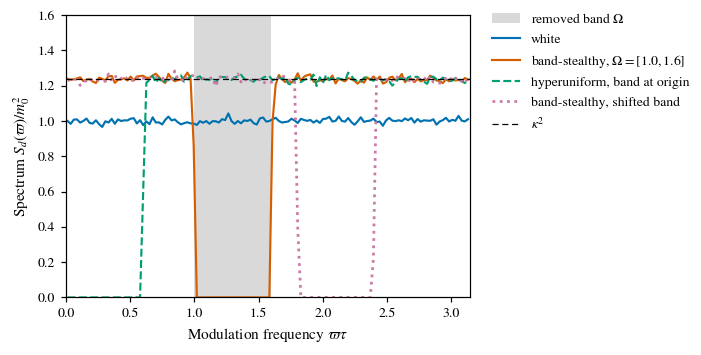

In [7]:
def binned(y, width=16):
    n = (len(y) - 1) // width
    return y[1:1 + n * width].reshape(n, width).mean(axis=1)

vp = 2 * np.pi * np.arange(N // 2 + 1) / N
vb = binned(vp)
fig, ax = fg.new(8.0)
fg.shade(ax, *BAND, color="0.85", label=r"removed band $\Omega$")
ax.plot(vb, binned(spectra["white"]), color=fg.BLUE, label="white")
ax.plot(vb, binned(spectra["stealthy"]), color=fg.VERMILION, label=r"band-stealthy, $\Omega=[1.0,1.6]$")
ax.plot(vb, binned(spectra["hyperuniform"]), color=fg.GREEN, ls="--", label=r"hyperuniform, band at origin")
ax.plot(vb, binned(spectra["shifted"]), color=fg.PURPLE, ls=":", lw=1.8, label=r"band-stealthy, shifted band")
ax.axhline(KAPPA2, color=fg.BLACK, lw=0.8, ls=(0, (5, 3)), label=r"$\kappa^2$")
ax.set_xlim(0, np.pi)
ax.set_ylim(0, 1.6)
ax.set_xlabel(r"Modulation frequency $\varpi\tau$")
ax.set_ylabel(r"Spectrum $S_d(\varpi)/m_0^2$")
fg.legend(fig)
fg.save(fig, "fig01_spectra")

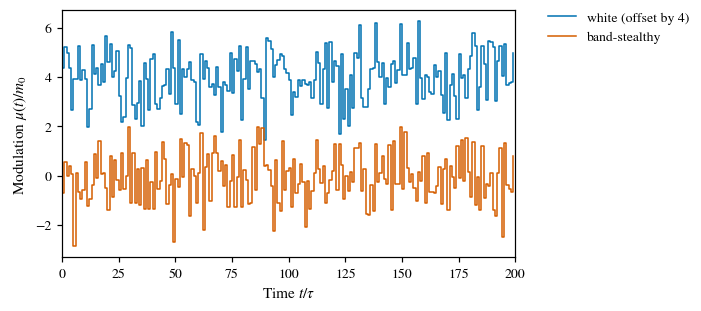

In [8]:
fig, ax = fg.new(7.0)
tt = np.arange(200)
ax.step(tt, seqs["white"][0, :200] / M0 + 4.0, where="post", color=fg.BLUE, lw=1.0, label="white (offset by 4)")
ax.step(tt, seqs["stealthy"][0, :200] / M0, where="post", color=fg.VERMILION, lw=1.0, label="band-stealthy")
ax.set_xlim(0, 200)
ax.set_xlabel(r"Time $t/\tau$")
ax.set_ylabel(r"Modulation $\mu(t)/m_0$")
fg.legend(fig)
fg.save(fig, "figS01_sequences")

### 5.4 Leading order, exact rate and Monte Carlo

Eq. (7) is exact for independent slabs; Eq. (6) is its leading term. A direct Monte Carlo
estimate of the mean-energy rate (4000 realizations, 256 slabs, slope of $\ln\langle E\rangle$,
jackknife errors) tests the propagator and the ensemble generator against Eq. (7). The
mean-energy estimator needs no crossover correction, because $\langle1+2\rho\rangle=e^{2\nu t}$
holds at all times in the diffusion limit.

In [9]:
mc_rows = []
for m0 in (0.05, 0.10, 0.20):
    for w in (0.40, 0.65, 1.00, 1.30):
        mu_mc = ens.white(ens.rng("validation", "mean-energy", m0, w), 4000, 256, m0)
        t_c, lnEf, _ = model.propagate(w, mu_mc, every=2)
        def slope_of_mean(rows):
            return model.ols_slopes(t_c, model.log_mean_energy(lnEf[rows])[None, :], FIT)[0]
        full = slope_of_mean(np.arange(4000))
        blocks = np.array_split(np.arange(4000), 10)
        jack = np.array([slope_of_mean(np.setdiff1d(np.arange(4000), blk)) for blk in blocks])
        se = float(np.sqrt(0.9 * ((jack - jack.mean())**2).sum()))
        exact = model.kronecker_rate(w, m0)
        born = float(model.born_rate_iid(w, m0))
        mc_rows.append((m0, w, full, se, exact, born))
mc_rows = np.array(mc_rows)
z_mc = (mc_rows[:, 2] - mc_rows[:, 4]) / mc_rows[:, 3]
print("  m0    omega   Monte Carlo        exact Eq.(7)   Born Eq.(6)   z(MC-exact)  exact/Born-1")
for row, z in zip(mc_rows, z_mc):
    print(f"{row[0]:5.2f} {row[1]:7.2f}   {row[2]:.4e}+-{row[3]:.1e}  {row[4]:.4e}   {row[5]:.4e}   "
          f"{z:+6.2f}      {row[4]/row[5]-1:+.4f}")
validation["mean_energy_rms_z"] = float(np.sqrt(np.mean(z_mc**2)))
validation["mean_energy_max_abs_z"] = float(np.abs(z_mc).max())
records.save_npz(RESULTS / "validation_mean_energy.npz", rows=mc_rows)

  m0    omega   Monte Carlo        exact Eq.(7)   Born Eq.(6)   z(MC-exact)  exact/Born-1
 0.05    0.40   1.9248e-04+-4.2e-06  1.8957e-04   1.8956e-04    +0.70      +0.0001
 0.05    0.65   4.5050e-04+-9.0e-06  4.5792e-04   4.5781e-04    -0.82      +0.0002
 0.05    1.00   8.8048e-04+-2.4e-05  8.8577e-04   8.8509e-04    -0.22      +0.0008
 0.05    1.30   1.1502e-03+-2.6e-05  1.1625e-03   1.1606e-03    -0.48      +0.0017
 0.10    0.40   7.4346e-04+-1.5e-05  7.5846e-04   7.5823e-04    -1.00      +0.0003
 0.10    0.65   1.8003e-03+-4.4e-05  1.8330e-03   1.8313e-03    -0.74      +0.0010
 0.10    1.00   3.5384e-03+-7.3e-05  3.5512e-03   3.5404e-03    -0.18      +0.0031
 0.10    1.30   4.7521e-03+-8.9e-05  4.6739e-03   4.6422e-03    +0.88      +0.0068
 0.20    0.40   3.0758e-03+-5.7e-05  3.0366e-03   3.0329e-03    +0.68      +0.0012
 0.20    0.65   7.1388e-03+-2.0e-04  7.3529e-03   7.3250e-03    -1.06      +0.0038
 0.20    1.00   1.4784e-02+-2.6e-04  1.4335e-02   1.4161e-02    +1.70      +0.01

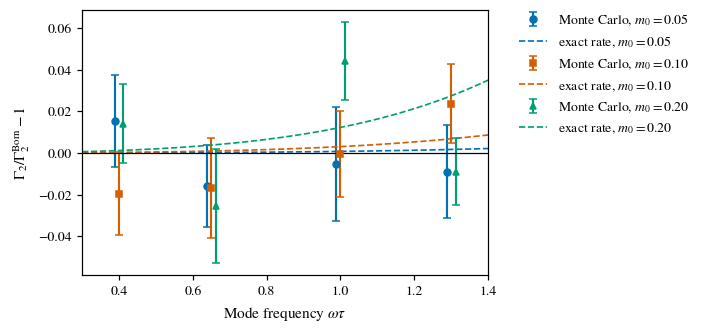

In [10]:
fig, ax = fg.new(7.5)
markers = {0.05: "o", 0.10: "s", 0.20: "^"}
colors = {0.05: fg.BLUE, 0.10: fg.VERMILION, 0.20: fg.GREEN}
wf = np.linspace(0.3, 1.4, 200)
for m0 in (0.05, 0.10, 0.20):
    sel = mc_rows[:, 0] == m0
    ax.plot(wf, np.array([model.kronecker_rate(w, m0) for w in wf]) / model.born_rate_iid(wf, m0) - 1,
            color=colors[m0], lw=1.1, ls="--", label=rf"exact rate, $m_0={m0:.2f}$")
    ax.errorbar(mc_rows[sel, 1] + {0.05: -0.012, 0.10: 0.0, 0.20: 0.012}[m0],
                mc_rows[sel, 2] / mc_rows[sel, 5] - 1, yerr=mc_rows[sel, 3] / mc_rows[sel, 5],
                fmt=markers[m0], color=colors[m0], capsize=2.5, label=rf"Monte Carlo, $m_0={m0:.2f}$")
ax.axhline(0.0, color=fg.BLACK, lw=0.8)
ax.set_xlim(0.3, 1.4)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"$\Gamma_2/\Gamma_2^{\rm Born}-1$")
fg.legend(fig, order=[rf"{k}, $m_0={m:.2f}$" for m in (0.05, 0.10, 0.20) for k in ("Monte Carlo", "exact rate")])
fg.save(fig, "figS04_mean_energy")

The Monte Carlo points scatter about the exact curves within their errors. The exact rate
itself departs from the leading-order Born rate by less than one percent at the primary depth
and by a few percent at $m_0=0.2$.

### 5.5 Heat kernel of the hyperbolic plane and the crossover function

The kernel of Eq. (10) must be normalized and must reproduce the two exact identities
$\langle\ln(1+\rho)\rangle=s$ and $\langle1+2\rho\rangle=e^{2s}$ (the second is dominated by
a far tail for $s\gtrsim5$ and is checked only below that).

In [11]:
print("    s      norm - 1     <ln(1+rho)> - s    <1+2rho> e^(-2s) - 1")
hk_err = []
for s in (0.001, 0.01, 0.1, 1.0, 3.0, 10.0, 30.0):
    mom = theory.hyperbolic_moments(s)
    e3 = mom["mean_1p2rho"] * np.exp(-2 * s) - 1 if s <= 3 else np.nan
    hk_err.append((abs(mom["norm"] - 1), abs(mom["ln1p_rho"] - s), abs(e3) if s <= 3 else 0.0))
    print(f"{s:7.3f}   {mom['norm']-1:+.1e}      {mom['ln1p_rho']-s:+.1e}          {e3:+.1e}")
validation["heat_kernel_max_error"] = float(np.max(hk_err))

x_tab = np.array([1e-3, 0.01, 0.05, 0.1, 0.3, 1.0, 3.0, 10.0, 40.0])
g_tab = theory.g_forward(x_tab, K=N // 2, window=FIT)
print("\n x = Gamma_typ N :", "  ".join(f"{v:g}" for v in x_tab))
print(" g_f(x)          :", "  ".join(f"{v:.4f}" for v in g_tab))
summary["crossover_table"] = {"x": x_tab.tolist(), "g_f": g_tab.tolist()}

    s      norm - 1     <ln(1+rho)> - s    <1+2rho> e^(-2s) - 1
  0.001   +2.5e-11      -5.0e-14          -1.0e-13
  0.010   +2.6e-11      -5.2e-13          -1.0e-12
  0.100   +2.8e-11      -5.8e-12          -9.9e-12
  1.000   +1.9e-11      -4.9e-11          -2.5e-11
  3.000   -1.9e-12      -5.0e-11          +1.6e-12
 10.000   -9.3e-12      +6.1e-11          +nan
 30.000   -2.5e-13      +7.2e-12          +nan

 x = Gamma_typ N : 0.001  0.01  0.05  0.1  0.3  1  3  10  40
 g_f(x)          : 1.9980  1.9805  1.9114  1.8399  1.6458  1.3552  1.1332  1.0204  1.0003


### 5.6 Residual theory for independent slabs

For independent slabs Eq. (14) can be compared with the exact rate of Eq. (7). Both deviate
from the Born rate at order $m_0^4$ in absolute terms; the table gives the fraction of the
exact correction that the phase-diffusion resummation reproduces.

In [12]:
pd_white_rows = []
for m0 in (0.05, 0.10, 0.20):
    pdw = theory.phase_diffusion_white(m0, 0.4)
    for w in (0.40, 0.65, 1.00, 1.30):
        born = float(model.born_rate_iid(w, m0))
        exact = model.kronecker_rate(w, m0)
        pd_rate = pdw.rate(w)
        pd_white_rows.append((m0, w, exact / born - 1, pd_rate / born - 1))
pd_white_rows = np.array(pd_white_rows)
frac = pd_white_rows[:, 3] / pd_white_rows[:, 2]
print("  m0   omega   exact/Born-1   Eq.(14)/Born-1   fraction captured")
for row, f in zip(pd_white_rows, frac):
    print(f"{row[0]:5.2f} {row[1]:6.2f}   {row[2]:+.5f}       {row[3]:+.5f}          {f:.2f}")
validation["pd_white_fraction_range"] = (float(frac.min()), float(frac.max()))
summary["validation"] = validation
records.save_json(RESULTS / "validation.json", validation)

  m0   omega   exact/Born-1   Eq.(14)/Born-1   fraction captured
 0.05   0.40   +0.00008       +0.00007          0.92
 0.05   0.65   +0.00024       +0.00020          0.83
 0.05   1.00   +0.00077       +0.00056          0.72
 0.05   1.30   +0.00170       +0.00115          0.67
 0.10   0.40   +0.00030       +0.00028          0.92
 0.10   0.65   +0.00096       +0.00079          0.83
 0.10   1.00   +0.00307       +0.00222          0.72
 0.10   1.30   +0.00682       +0.00457          0.67
 0.20   0.40   +0.00120       +0.00110          0.92
 0.20   0.65   +0.00380       +0.00314          0.83
 0.20   1.00   +0.01227       +0.00880          0.72
 0.20   1.30   +0.02742       +0.01813          0.66


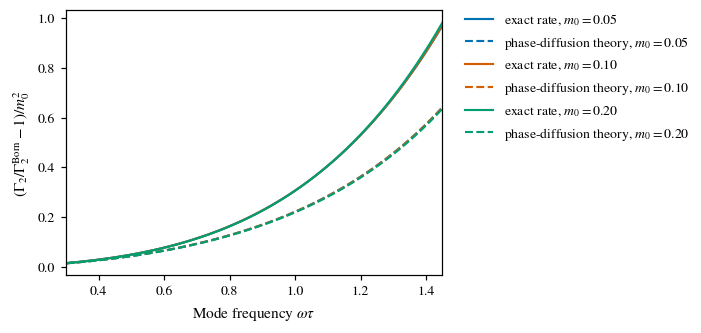

In [13]:
fig, ax = fg.new(7.5)
wf = np.linspace(0.3, 1.45, 60)
for m0, col in ((0.05, fg.BLUE), (0.10, fg.VERMILION), (0.20, fg.GREEN)):
    pdw = theory.phase_diffusion_white(m0, 0.3)
    born = model.born_rate_iid(wf, m0)
    ex = np.array([model.kronecker_rate(w, m0) for w in wf])
    pdr = np.array([pdw.rate(w) for w in wf])
    ax.plot(wf, (ex / born - 1) / m0**2, color=col, label=rf"exact rate, $m_0={m0:.2f}$")
    ax.plot(wf, (pdr / born - 1) / m0**2, color=col, ls="--", label=rf"phase-diffusion theory, $m_0={m0:.2f}$")
ax.set_xlim(0.3, 1.45)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"$(\Gamma_2/\Gamma_2^{\rm Born}-1)/m_0^2$")
fg.legend(fig)
fg.save(fig, "figS02_white_correction")

## 6. Production ensembles

### 6.1 Primary grids

Three ensembles are propagated at every mode frequency and every depth, with $M=400$
realizations of $N=4096$ slabs each:

* **white**: independent Gaussian slabs;
* **band-stealthy**: the construction of Section 3 with $\Omega=[1.0,1.6]$;
* **shuffled**: each band-stealthy sequence randomly permuted, which keeps its values and
  destroys its correlations.

For every realization the least-squares slopes of $\ln E$ are recorded for the forward and
the standing-wave launch, on four fit windows, using the energy after every second slab.

In [14]:
ENSEMBLES = ("white", "stealthy", "shuffled")


def make_draw(kind, m0, n_slabs=N, bins=BINS, tag="primary"):
    # draw(i, m) returns m sequences for frequency index i of the given ensemble
    def draw(i, m):
        g = ens.rng(tag, kind, m0, i, n_slabs)
        if kind == "white":
            return ens.white(g, m, n_slabs, m0)
        x = ens.stealthy(g, m, n_slabs, m0, bins)
        return ens.shuffled(g, x) if kind == "shuffled" else x
    return draw


shape = (len(ENSEMBLES), len(DEPTHS), len(FIT_WINDOWS), len(OMEGA))
fwd_mean, fwd_se = np.empty(shape), np.empty(shape)
std_mean, std_se = np.empty(shape), np.empty(shape)
lnEbar = np.empty((len(ENSEMBLES), len(DEPTHS), len(OMEGA), N // 32))
slopes_centre = {}
for e, kind in enumerate(ENSEMBLES):
    t0 = time.time()
    for d, m0 in enumerate(DEPTHS):
        run = simulate.run_grid(OMEGA, make_draw(kind, m0), M, N, windows=FIT_WINDOWS)
        fwd_mean[e, d], fwd_se[e, d] = simulate.mean_se(run["forward"])
        std_mean[e, d], std_se[e, d] = simulate.mean_se(run["standing"])
        lnEbar[e, d] = run["lnEbar"]
        if d == I_PRIMARY:
            slopes_centre[kind] = run["forward"][0, I_CENTRE].copy()
    print(f"{kind:9s}: {len(DEPTHS)} depths x {len(OMEGA)} frequencies x {M} realizations "
          f"in {time.time() - t0:5.1f} s")
t_coarse = run["t"]

G2W = np.array([[model.kronecker_rate(w, m0) for w in OMEGA] for m0 in DEPTHS])   # Eq. (7)
GtypW = G2W / 2                                                                   # Eq. (9)
records.save_npz(RESULTS / "primary_grid.npz", omega=OMEGA, depths=DEPTHS,
                    windows=np.array(FIT_WINDOWS), fwd_mean=fwd_mean, fwd_se=fwd_se,
                    std_mean=std_mean, std_se=std_se, lnEbar=lnEbar, t_coarse=t_coarse,
                    G2_white_exact=G2W, **{f"slopes_centre_{k}": v for k, v in slopes_centre.items()})

white    : 6 depths x 53 frequencies x 400 realizations in 113.7 s
stealthy : 6 depths x 53 frequencies x 400 realizations in 123.1 s
shuffled : 6 depths x 53 frequencies x 400 realizations in 133.1 s


Every forward-launch slope is converted into the mean-energy rate $\hat\Gamma_2$ by inverting
the crossover function (Section 2), separately for each fit window.

In [15]:
def gamma2_hat(mean, se, n_slabs=N, window=FIT):
    return theory.gamma2_from_forward(mean, se, n_slabs, K=n_slabs // 2, window=window)


G2, G2se = np.empty(shape), np.empty(shape)
t0 = time.time()
for e in range(len(ENSEMBLES)):
    for d in range(len(DEPTHS)):
        for w_i, win in enumerate(FIT_WINDOWS):
            G2[e, d, w_i], G2se[e, d, w_i] = gamma2_hat(fwd_mean[e, d, w_i], fwd_se[e, d, w_i], N, win)
print(f"inverted {G2.size} slopes in {time.time() - t0:.1f} s")
xS = G2[1, :, 0] * N / 2
print("largest x = Gamma_typ N of the band-stealthy ensemble inside the window, per depth:",
      np.round(xS[:, INNER].max(axis=1), 4))
summary["xS_max_inner"] = {f"{m0:g}": float(xS[d, INNER].max()) for d, m0 in enumerate(DEPTHS)}

inverted 3816 slopes in 3.0 s
largest x = Gamma_typ N of the band-stealthy ensemble inside the window, per depth: [2.0000e-04 7.1000e-03 4.3700e-02 1.0970e-01 6.6430e-01 2.1089e+00]


### 6.2 Horizons and independent seed families

The white ensemble at the primary depth is repeated on horizons of 1024, 8192 and 16384
slabs, for the crossover test of Section 7. For the band-stealthy ensemble, twelve
independent families of 400 realizations are generated at the interior frequencies of the
window on each of the four horizons, with the constrained bins recomputed for each $N$. At
$N=4096$ the slopes are recorded on all four fit windows. Pooling the families gives 4800
realizations per frequency; resampling whole families gives the statistical uncertainty.

In [ ]:
hor_white = {N: (fwd_mean[0, I_PRIMARY, 0], fwd_se[0, I_PRIMARY, 0], std_mean[0, I_PRIMARY, 0], std_se[0, I_PRIMARY, 0])}
t0 = time.time()
for n_h in HORIZONS:
    if n_h != N:
        run = simulate.run_grid(OMEGA, make_draw("white", M0, n_h, tag="horizon"), M, n_h, windows=[FIT])
        hor_white[n_h] = simulate.mean_se(run["forward"][0]) + simulate.mean_se(run["standing"][0])
print(f"white ensembles on the other horizons in {time.time() - t0:.1f} s")

omega_in = OMEGA[INNER]
fam = {}                          # horizon -> (mean, se), each (FAMILIES, n_windows, n_inner)
for n_h in HORIZONS:
    t0 = time.time()
    bins_h = ens.band_bins(n_h, BAND)
    wins = FIT_WINDOWS if n_h == N else [FIT]
    mean_h = np.empty((FAMILIES, len(wins), len(omega_in)))
    se_h = np.empty_like(mean_h)
    for f in range(FAMILIES):
        def draw(i, m, f=f, n_h=n_h, bins_h=bins_h):
            return ens.stealthy(ens.rng("family", n_h, f, i), m, n_h, M0, bins_h)
        run = simulate.run_grid(omega_in, draw, M, n_h, windows=wins)
        mean_h[f], se_h[f] = simulate.mean_se(run["forward"])
    fam[n_h] = (mean_h, se_h)
    print(f"N = {n_h:5d}: {FAMILIES} band-stealthy families in {time.time() - t0:5.1f} s")
records.save_npz(RESULTS / "horizons_families.npz", horizons=np.array(HORIZONS), omega_inner=omega_in,
                    windows=np.array(FIT_WINDOWS), **{f"white_{n_h}": np.array(v) for n_h, v in hor_white.items()},
                    **{f"family_mean_{n_h}": v[0] for n_h, v in fam.items()},
                    **{f"family_se_{n_h}": v[1] for n_h, v in fam.items()})

## 7. Finite-horizon crossover and estimator checks

Every white point, at every depth and horizon, has a known exact rate, so its typical slope
can be compared with the prediction $\Gamma_{\rm typ}\,g_f(x)$ with no free parameter. The
standing-wave launch should instead give $\Gamma_{\rm typ}$ at every $x$.

In [ ]:
rows = []                         # x, forward slope/Gtyp, se, standing slope/Gtyp, se, N
for d, m0 in enumerate(DEPTHS):
    gt = GtypW[d]
    rows += [(gt[i] * N, fwd_mean[0, d, 0, i] / gt[i], fwd_se[0, d, 0, i] / gt[i],
              std_mean[0, d, 0, i] / gt[i], std_se[0, d, 0, i] / gt[i], N) for i in range(len(OMEGA))]
for n_h in HORIZONS:
    if n_h == N:
        continue
    fm, fs, sm, ss = hor_white[n_h]
    gt = GtypW[I_PRIMARY]
    rows += [(gt[i] * n_h, fm[i] / gt[i], fs[i] / gt[i], sm[i] / gt[i], ss[i] / gt[i], n_h)
             for i in range(len(OMEGA))]
rows = np.array(rows)
g_pred = np.array([theory.g_forward(r[0], K=int(r[5]) // 2, window=FIT)[0] for r in rows])
z_fwd = (rows[:, 1] - g_pred) / rows[:, 2]
z_std = (rows[:, 3] - 1.0) / rows[:, 4]
std_ratio_mean = float(rows[:, 3].mean())
std_ratio_se = float(np.sqrt(np.sum(rows[:, 4]**2)) / len(rows))
crossover = {"n_points": len(rows), "forward_mean_z": float(z_fwd.mean()),
             "forward_rms_z": float(np.sqrt(np.mean(z_fwd**2))),
             "standing_mean_ratio": std_ratio_mean, "standing_mean_ratio_se": std_ratio_se,
             "standing_mean_z": float(z_std.mean()), "standing_rms_z": float(np.sqrt(np.mean(z_std**2))),
             "x_range": (float(rows[:, 0].min()), float(rows[:, 0].max()))}
print(f"{len(rows)} white points, x from {rows[:, 0].min():.3f} to {rows[:, 0].max():.1f}")
print(f"forward launch : mean z = {z_fwd.mean():+.3f}, rms z = {np.sqrt(np.mean(z_fwd**2)):.3f}")
print(f"standing wave  : mean slope/Gamma_typ = {std_ratio_mean:.4f} +- {std_ratio_se:.4f}, "
      f"rms z = {crossover['standing_rms_z']:.3f}")
x_edges = np.array([0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0])
binned_rows = []
print("\n   x range        forward slope/Gtyp       g_f(x)   standing slope/Gtyp   points")
for lo, hi in zip(x_edges[:-1], x_edges[1:]):
    sel = (rows[:, 0] >= lo) & (rows[:, 0] < hi)
    if sel.sum() < 2:
        continue
    n_sel = sel.sum()
    f_m, f_e = rows[sel, 1].mean(), np.sqrt(np.sum(rows[sel, 2]**2)) / n_sel
    s_m, s_e = rows[sel, 3].mean(), np.sqrt(np.sum(rows[sel, 4]**2)) / n_sel
    binned_rows.append((np.exp(np.log(rows[sel, 0]).mean()), f_m, f_e, s_m, s_e, g_pred[sel].mean()))
    print(f"[{lo:6.2f},{hi:6.1f})   {f_m:.3f} +- {f_e:.3f}      {g_pred[sel].mean():.3f}    "
          f"{s_m:.3f} +- {s_e:.3f}       {n_sel}")
binned_rows = np.array(binned_rows)
summary["crossover"] = crossover

In [ ]:
fig, ax = fg.new(8.0)
xs = np.geomspace(1e-3, 300, 300)
ax.plot(rows[:, 0], rows[:, 1], "o", ms=2.2, color=fg.SKY, alpha=0.6, ls="none",
        label="white, forward launch, single frequency")
ax.plot(rows[:, 0], rows[:, 3], "s", ms=2.2, color=fg.ORANGE, alpha=0.5, ls="none",
        label="white, standing-wave launch, single frequency")
ax.plot(xs, theory.g_forward(xs, K=N // 2, window=FIT), color=fg.BLACK, lw=1.4,
        label=r"$g_f(x)$, heat-kernel theory")
ax.axhline(1.0, color=fg.BLACK, lw=1.0, ls="--", label=r"$g_b=1$, standing wave")
ax.errorbar(binned_rows[:, 0], binned_rows[:, 1], yerr=binned_rows[:, 2], fmt="o", ms=5.5, color=fg.BLUE,
            capsize=2.5, label="white, forward launch, binned mean")
ax.errorbar(binned_rows[:, 0], binned_rows[:, 3], yerr=binned_rows[:, 4], fmt="s", ms=5.5, color=fg.VERMILION,
            capsize=2.5, label="white, standing-wave launch, binned mean")
ax.set_xscale("log")
fg.log_ticks(ax, "x")
ax.set_xlim(1e-3, 300)
ax.set_ylim(0.4, 2.6)
ax.set_xlabel(r"$x=\Gamma_{\rm typ}N$")
ax.set_ylabel(r"Typical slope / $\Gamma_{\rm typ}$")
fg.legend(fig, order=["white, forward launch, binned mean", "white, forward launch, single frequency",
                      r"$g_f(x)$, heat-kernel theory", "white, standing-wave launch, binned mean",
                      "white, standing-wave launch, single frequency", r"$g_b=1$, standing wave"])
fg.save(fig, "fig02_crossover")

The forward-launch points of all depths and horizons collapse on the parameter-free curve
$g_f(x)$, and the standing-wave points sit at one. The collapse is what allows the
protection factor to be formed from rates rather than from slopes measured at different
$x$.

For the band-stealthy ensemble inside the window $x\ll1$, and the standing-wave estimator
is dominated by the interference term $2\sqrt{\rho(1+\rho)}\cos\theta$ of $E_s$: it is
unbiased but far noisier than the forward launch, as the next cell shows. All band-stealthy
rates below therefore use the forward launch.

In [ ]:
ratio_std = std_mean[1, I_PRIMARY, 0, INNER] / (G2[1, I_PRIMARY, 0, INNER] / 2)
z_std_s = (std_mean[1, I_PRIMARY, 0, INNER] - G2[1, I_PRIMARY, 0, INNER] / 2) / std_se[1, I_PRIMARY, 0, INNER]
rel_se_fwd = np.median(G2se[1, I_PRIMARY, 0, INNER] / G2[1, I_PRIMARY, 0, INNER])
rel_se_std = np.median(std_se[1, I_PRIMARY, 0, INNER] / (G2[1, I_PRIMARY, 0, INNER] / 2))
print(f"band-stealthy, interior window: standing slope vs Gamma_2/2: rms z = {np.sqrt(np.mean(z_std_s**2)):.2f}")
print(f"median relative standard error: forward {rel_se_fwd:.3f}, standing wave {rel_se_std:.1f}")
summary["stealthy_standing"] = {"rms_z": float(np.sqrt(np.mean(z_std_s**2))),
                                "rel_se_forward": float(rel_se_fwd), "rel_se_standing": float(rel_se_std)}

fig, ax = fg.new(7.5)
for kind, col, lab in (("white", fg.BLUE, "white"), ("stealthy", fg.VERMILION, "band-stealthy")):
    s = slopes_centre[kind]
    ax.hist(s / s.mean(), bins=np.linspace(-1, 5, 31), histtype="step", lw=1.4, color=col, density=True,
            label=f"{lab}, mean slope " + fg.sci(s.mean()))
ax.set_xlim(-1, 5)
ax.set_xlabel(r"Slope of $\ln E$ divided by its ensemble mean")
ax.set_ylabel("Probability density")
fg.legend(fig)
fg.save(fig, "figS03_slope_distributions")

## 8. Protection factor

The protection factor of Eq. (11) uses the exact white rate and the band-stealthy estimate
$\hat\Gamma_{2,S}$. A point is resolved when $\hat\Gamma_{2,S}$ exceeds twice its standard
error; otherwise only the lower bound $R>\Gamma_{2,W}/(\max(\hat\Gamma_{2,S},0)+2\sigma)$ is
reported.

The headline number is the median of $R(\omega)$ over the interior of the window at the
primary depth, from the twelve pooled seed families (4800 realizations per frequency). Its
uncertainty comes from resampling whole families.

In [ ]:
def protection(g2w, g2s, se):
    resolved = g2s > 2 * se
    R = np.where(resolved, g2w / np.where(resolved, g2s, 1.0), g2w / (np.maximum(g2s, 0) + 2 * se))
    return R, resolved


def pooled_rate(mean, se, n_slabs=N, window=FIT):
    # rate estimate from families pooled along axis 0
    return gamma2_hat(mean.mean(axis=0), np.sqrt((se**2).sum(axis=0)) / len(mean), n_slabs, window)


def pooled_R(mean, se, n_slabs=N, window=FIT):
    # median protection factor over the interior of the window
    return float(np.median(G2W[I_PRIMARY, INNER] / pooled_rate(mean, se, n_slabs, window)[0]))


R_grid, R_ok = protection(G2W, G2[1, :, 0], G2se[1, :, 0])

fam_mean, fam_se = fam[N][0][:, 0], fam[N][1][:, 0]
pool_G2, pool_G2se = pooled_rate(fam_mean, fam_se)
R_pool = G2W[I_PRIMARY, INNER] / pool_G2
R_head = float(np.median(R_pool))

picks = ens.rng("bootstrap", "families").integers(0, FAMILIES, (2000, FAMILIES))
boot = np.array([pooled_R(fam_mean[p], fam_se[p]) for p in picks])
fam_medians = np.array([pooled_R(fam_mean[f:f + 1], fam_se[f:f + 1]) for f in range(FAMILIES)])
R_primary = float(np.median(R_grid[I_PRIMARY, INNER]))

pd_M0 = theory.phase_diffusion_bands(M0, [BAND], OMEGA[INNER].min(), t_min=max(HORIZONS))
pd_in = np.array([pd_M0.rate(w) for w in OMEGA[INNER]])
R_theory_in = G2W[I_PRIMARY, INNER] / pd_in

headline = {"R_median": R_head, "R_boot_16_84": np.percentile(boot, [16, 84]).tolist(),
            "R_boot_sd": float(boot.std(ddof=1)), "R_interior_min": float(R_pool.min()),
            "R_interior_max": float(R_pool.max()), "R_primary_grid_median": R_primary,
            "family_median_mean": float(fam_medians.mean()), "family_median_sd": float(fam_medians.std(ddof=1)),
            "R_theory_median": float(np.median(R_theory_in)),
            "G2_stealthy_pooled_median": float(np.median(pool_G2)),
            "G2_white_interior_median": float(np.median(G2W[I_PRIMARY, INNER]))}
summary["headline"] = headline
print(f"median R over the interior of the window (m0 = {M0}, {FAMILIES * M} realizations per frequency): "
      f"{R_head:.0f} +- {headline['R_boot_sd']:.0f} (family bootstrap)")
print(f"interior range of R: {R_pool.min():.0f} to {R_pool.max():.0f}")
print(f"single {M}-realization family: median R = {fam_medians.mean():.0f} +- {fam_medians.std(ddof=1):.0f} "
      f"(primary grid: {R_primary:.0f})")
print(f"Eq. (14) prediction for the median: {np.median(R_theory_in):.0f}")
print("\n omega    R (pooled)   R (Eq. 14)")
for w, r1, r2 in zip(OMEGA[INNER], R_pool, R_theory_in):
    print(f"{w:6.3f}    {r1:7.0f}      {r2:7.0f}")

In [ ]:
pd_all = np.array([pd_M0.rate(w) for w in OMEGA])
wf = np.linspace(0.2, 1.5, 400)
fig, ax = fg.new(8.5)
fg.shade(ax, *WINDOW, label=r"protected window $\Omega/2$")
ax.plot(wf, [model.kronecker_rate(w, M0) for w in wf], color=fg.BLUE, lw=1.4, label="white, exact rate")
ax.errorbar(OMEGA, G2[0, I_PRIMARY, 0], yerr=G2se[0, I_PRIMARY, 0], fmt="o", ms=3.5, color=fg.BLUE,
            mfc="white", elinewidth=0.7, label="white, simulation")
ax.plot(OMEGA, pd_all, color=fg.VERMILION, lw=1.4, label="band-stealthy, phase-diffusion theory")
ok = R_ok[I_PRIMARY]
ax.errorbar(OMEGA[ok], G2[1, I_PRIMARY, 0, ok], yerr=G2se[1, I_PRIMARY, 0, ok], fmt="s", ms=3.5,
            color=fg.VERMILION, elinewidth=0.7, label="band-stealthy, simulation")
ax.errorbar(OMEGA[INNER], pool_G2, yerr=pool_G2se, fmt="D", ms=3.5, color=fg.BLACK, mfc="none",
            elinewidth=0.7, label=f"band-stealthy, {FAMILIES} pooled families")
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(0.2, 1.5)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"Mean-energy growth rate $\Gamma_2\tau$")
fg.legend(fig)
fg.save(fig, "fig03_rates")

In [ ]:
fig, ax = fg.new(8.5)
fg.shade(ax, *WINDOW)
depth_colors = [fg.BLUE, fg.VERMILION, fg.GREEN, fg.ORANGE, fg.PURPLE, fg.SKY]
depth_markers = ["o", "s", "^", "D", "v", "P"]
for d, m0 in enumerate(DEPTHS):
    col, mk = depth_colors[d], depth_markers[d]
    ok = R_ok[d]
    ax.plot(OMEGA[ok], R_grid[d, ok], mk, ms=3.8, color=col, ls="-", lw=0.8,
            label=rf"$m_0={m0:g}$")
    if (~ok).any():
        ax.plot(OMEGA[~ok], R_grid[d, ~ok], mk, ms=4.2, mfc="none", color=col, ls="none")
ax.axhline(1 / KAPPA2, color=fg.BLACK, lw=0.8, ls="--", label=r"$1/\kappa^2$")
ax.plot([], [], "o", mfc="none", color="0.3", label="lower bound (open)")
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(0.2, 1.5)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"Protection factor $R=\Gamma_{2,W}/\hat\Gamma_{2,S}$")
fg.legend(fig)
fg.save(fig, "fig04_protection")
summary["R_grid_interior_median"] = {f"{m0:g}": float(np.median(R_grid[d, INNER])) for d, m0 in enumerate(DEPTHS)}
summary["R_grid_interior_resolved"] = {f"{m0:g}": int(R_ok[d, INNER].sum()) for d, m0 in enumerate(DEPTHS)}
print("interior median R per depth:", {k: round(v) for k, v in summary["R_grid_interior_median"].items()})
print("resolved interior points per depth:", summary["R_grid_interior_resolved"])

## 9. Depth scaling and the residual theory

Outside the window the band-stealthy rate is first order in the spectrum and scales as
$m_0^2$. Inside, Eq. (14) predicts $m_0^4$. The exponents are fitted to the medians over the
interior and over the out-of-window modes, using the depths at which every interior point
is resolved. The phase-diffusion prediction is evaluated on the same horizon and fit window
as the simulations (`finite_horizon_slope`), which matters only for the smallest depth.

In [ ]:
pd_objects = {}
pd_fh = np.empty((len(DEPTHS), len(OMEGA)))            # finite-horizon prediction, N = 4096
pd_st = np.empty((len(DEPTHS), len(OMEGA)))            # stationary Eq. (14)
t0 = time.time()
for d, m0 in enumerate(DEPTHS):
    pdo = theory.phase_diffusion_bands(m0, [BAND], OMEGA[INNER].min(), t_min=max(HORIZONS),
                                       dtau=1 / 16 if m0 < 0.03 else 1 / 32)
    pd_objects[m0] = pdo
    pd_st[d] = [pdo.rate(w) for w in OMEGA]
    pd_fh[d, INNER] = [pdo.finite_horizon_slope(w, N) for w in OMEGA[INNER]]
    pd_fh[d, ~INNER] = np.nan
print(f"Eq. (14) evaluated for {len(DEPTHS)} depths in {time.time() - t0:.1f} s")

med_in = np.array([np.median(G2[1, d, 0, INNER]) for d in range(len(DEPTHS))])
med_in_se = np.array([1.2533 * np.sqrt(np.mean(G2se[1, d, 0, INNER]**2) / INNER.sum())
                      for d in range(len(DEPTHS))])
med_out = np.array([np.median(G2[1, d, 0, OUTER]) for d in range(len(DEPTHS))])
med_out_w = np.array([np.median(G2W[d, OUTER]) for d in range(len(DEPTHS))])
th_in = np.array([np.median(pd_fh[d, INNER]) for d in range(len(DEPTHS))])
all_resolved = np.array([R_ok[d, INNER].all() for d in range(len(DEPTHS))])


def loglog_fit(x, y):
    A = np.vstack([np.log(x), np.ones_like(x)]).T
    coef, res, *_ = np.linalg.lstsq(A, np.log(y), rcond=None)
    dof = max(len(x) - 2, 1)
    s2 = float(np.sum((np.log(y) - A @ coef)**2)) / dof
    cov = s2 * np.linalg.inv(A.T @ A)
    return coef[0], np.sqrt(cov[0, 0])


p_in, p_in_se = loglog_fit(DEPTHS[all_resolved], med_in[all_resolved])
p_out, p_out_se = loglog_fit(DEPTHS, med_out)
p_th, _ = loglog_fit(DEPTHS[all_resolved], th_in[all_resolved])
p_R, p_R_se = loglog_fit(DEPTHS[all_resolved], np.array(list(summary["R_grid_interior_median"].values()))[all_resolved])
scaling = {"depths_fitted_in": DEPTHS[all_resolved].tolist(), "p_in": float(p_in), "p_in_se": float(p_in_se),
           "p_out": float(p_out), "p_out_se": float(p_out_se), "p_theory_in": float(p_th),
           "p_R": float(p_R), "p_R_se": float(p_R_se),
           "median_in": med_in.tolist(), "median_out": med_out.tolist(), "theory_in": th_in.tolist()}
summary["scaling"] = scaling
print("depth    median in window     Eq.(14)      median outside   resolved")
for d, m0 in enumerate(DEPTHS):
    print(f"{m0:5.3f}   {med_in[d]:.3e}+-{med_in_se[d]:.1e}   {th_in[d]:.3e}   {med_out[d]:.3e}      {all_resolved[d]}")
print(f"\nexponent inside the window  {p_in:.2f} +- {p_in_se:.2f} (Eq. 14: {p_th:.2f})")
print(f"exponent outside the window {p_out:.2f} +- {p_out_se:.2f}")
print(f"exponent of the median protection factor {p_R:.2f} +- {p_R_se:.2f}")

In [ ]:
mf = np.geomspace(0.015, 0.25, 50)
fig, ax = fg.new(8.0)
ax.errorbar(DEPTHS[all_resolved], med_in[all_resolved], yerr=med_in_se[all_resolved], fmt="s",
            color=fg.VERMILION, ms=5, label="band-stealthy, inside the window")
if (~all_resolved).any():
    ax.plot(DEPTHS[~all_resolved], np.maximum(med_in[~all_resolved], 2 * med_in_se[~all_resolved]), "s",
            mfc="none", color=fg.VERMILION, ms=5, label="inside, not resolved (upper value)")
ax.plot(DEPTHS, th_in, color=fg.VERMILION, lw=1.2, ls="--", label="phase-diffusion theory, inside")
ax.plot(DEPTHS, med_out, "o", color=fg.BLUE, ms=5, label="band-stealthy, outside the window")
ax.plot(DEPTHS, med_out_w * KAPPA2, color=fg.BLUE, lw=1.2, ls="--", label=r"$\kappa^2\times$ exact white, outside")
ax.plot(mf, med_out[1] * (mf / DEPTHS[1])**2, color="0.55", lw=0.9, ls=":", label=r"slopes 2 and 4")
ax.plot(mf, med_in[3] * (mf / DEPTHS[3])**4, color="0.55", lw=0.9, ls=":")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.fixed_ticks(ax, "x", [0.02, 0.05, 0.1, 0.2])
ax.set_xlim(0.015, 0.25)
ax.set_xlabel(r"Modulation depth $m_0$")
ax.set_ylabel(r"Median $\hat\Gamma_{2,S}\tau$")
fg.legend(fig, order=["band-stealthy, inside the window", "inside, not resolved (upper value)",
                      "phase-diffusion theory, inside", "band-stealthy, outside the window",
                      r"$\kappa^2\times$ exact white, outside", "slopes 2 and 4"])
fg.save(fig, "fig06_depth_scaling")

The comparison below is made point by point inside the window, for every depth at which the
residual is resolved. Dividing by $m_0^4$ should collapse the band-stealthy rates onto a
single U-shaped profile if the residual is of fourth order.

In [ ]:
ratio_rows = []
for d, m0 in enumerate(DEPTHS):
    if not all_resolved[d]:
        continue
    r = G2[1, d, 0, INNER] / pd_fh[d, INNER]
    ratio_rows.append((m0, np.median(r), r.min(), r.max()))
    print(f"m0 = {m0:5.3f}: simulation / Eq. (14): median {np.median(r):.3f}, range {r.min():.2f} to {r.max():.2f}")
summary["residual_theory_ratio"] = {f"{row[0]:g}": {"median": float(row[1]), "min": float(row[2]),
                                                    "max": float(row[3])} for row in ratio_rows}

fig, ax = fg.new(8.5)
wf = np.linspace(OMEGA[INNER].min(), OMEGA[INNER].max(), 120)
for d, m0 in enumerate(DEPTHS):
    if not all_resolved[d]:
        continue
    col, mk = depth_colors[d], depth_markers[d]
    ax.errorbar(OMEGA[INNER], G2[1, d, 0, INNER] / m0**4, yerr=G2se[1, d, 0, INNER] / m0**4, fmt=mk,
                color=col, ms=4, elinewidth=0.7, capsize=2, label=rf"simulation, $m_0={m0:g}$")
    ax.plot(wf, [pd_objects[m0].finite_horizon_slope(w, N) / m0**4 for w in wf], color="0.25", lw=0.9,
            label="phase-diffusion theory, one curve per depth" if d == I_PRIMARY else None)
ax.set_yscale("log")
fg.fixed_ticks(ax, "y", [0.1, 0.2, 0.3, 0.5, 0.8])
ax.set_ylim(0.07, 1.0)
ax.set_xlim(0.51, 0.79)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"$\hat\Gamma_{2,S}\tau/m_0^4$")
fg.legend(fig)
fg.save(fig, "fig05_residual")

## 10. Redistribution cost for unprotected modes

Outside the window the band-stealthy ensemble carries the spectral weight removed from the
band. At leading order its rate is $\kappa^2$ times the white rate, Eq. (12), with no
adjustable parameter. The shuffled ensemble has the same values but no correlations, and
must reproduce the white rate.

In [ ]:
redis = {}
for d, m0 in enumerate(DEPTHS):
    r = G2[1, d, 0, OUTER] / G2W[d, OUTER]
    th = np.array([pd_objects[m0].rate(w) for w in OMEGA[OUTER]]) / G2W[d, OUTER]
    shuf = G2[2, d, 0] / G2W[d]
    redis[f"{m0:g}"] = {"ratio": float(r.mean()), "se": float(r.std(ddof=1) / np.sqrt(r.size)),
                        "theory_ratio": float(th.mean()),
                        "shuffled_ratio": float(shuf.mean()), "shuffled_se": float(shuf.std(ddof=1) / np.sqrt(shuf.size))}
    v = redis[f"{m0:g}"]
    print(f"m0 = {m0:5.3f}: outside ratio {v['ratio']:.4f} +- {v['se']:.4f}; Eq. (14) / exact white {v['theory_ratio']:.4f}; "
          f"kappa^2 = {KAPPA2:.4f}; shuffled / white {v['shuffled_ratio']:.4f} +- {v['shuffled_se']:.4f}")
vals = np.array([[v["ratio"], v["se"], v["theory_ratio"], v["shuffled_ratio"], v["shuffled_se"]] for v in redis.values()])
wts = vals[:, 1]**-2
redis_pooled = float(np.average(vals[:, 0], weights=wts))
redis_pooled_se = float(np.sqrt(1 / wts.sum()))
z_theory = (vals[:, 0] - vals[:, 2]) / vals[:, 1]
shuf_pooled = float(np.average(vals[:, 3], weights=vals[:, 4]**-2))
shuf_pooled_se = float(np.sqrt(1 / np.sum(vals[:, 4]**-2)))
print(f"\npooled over depths: {redis_pooled:.4f} +- {redis_pooled_se:.4f} "
      f"({(redis_pooled - KAPPA2) / redis_pooled_se:+.2f} sigma from kappa^2); "
      f"per-depth deviation from Eq. (14): rms z = {np.sqrt(np.mean(z_theory**2)):.2f}")
print(f"shuffled / white pooled over depths: {shuf_pooled:.4f} +- {shuf_pooled_se:.4f}")
summary["redistribution"] = {"per_depth": redis, "pooled": redis_pooled, "pooled_se": redis_pooled_se,
                             "kappa2": KAPPA2, "rms_z_vs_theory": float(np.sqrt(np.mean(z_theory**2))),
                             "shuffled_pooled": shuf_pooled, "shuffled_pooled_se": shuf_pooled_se}

In [ ]:
fig, ax = fg.new(7.5)
mf = np.linspace(0.0, 0.22, 50)
th_line = [np.mean([pd_objects[m0].rate(w) for w in OMEGA[OUTER]] / G2W[d, OUTER]) for d, m0 in enumerate(DEPTHS)]
ax.errorbar(DEPTHS, vals[:, 0], yerr=vals[:, 1], fmt="s", color=fg.VERMILION, ms=5, capsize=2.5,
            label="band-stealthy, mean over out-of-window modes")
ax.plot(DEPTHS, th_line, color=fg.VERMILION, lw=1.1, ls="--", label="phase-diffusion theory / exact white rate")
ax.errorbar(DEPTHS, vals[:, 3], yerr=vals[:, 4], fmt="x", color="0.3", ms=6, capsize=2.5,
            label="shuffled, mean over all modes")
ax.axhline(KAPPA2, color=fg.BLACK, lw=1.2, label=r"$\kappa^2$")
ax.axhline(1.0, color=fg.BLACK, lw=0.9, ls=":", label="white")
ax.set_xlim(0.0, 0.22)
ax.set_ylim(0.9, 1.35)
ax.set_xlabel(r"Modulation depth $m_0$")
ax.set_ylabel(r"$\hat\Gamma_2/\Gamma_{2,W}$")
fg.legend(fig, order=["band-stealthy, mean over out-of-window modes", "phase-diffusion theory / exact white rate",
                      r"$\kappa^2$", "shuffled, mean over all modes", "white"])
fg.save(fig, "fig07_redistribution")

fig, ax = fg.new(8.0)
fg.shade(ax, 0.45, 0.85, color="0.92")
for d, m0 in enumerate(DEPTHS):
    ax.errorbar(OMEGA[OUTER] + (d - 2.5) * 0.003, G2[1, d, 0, OUTER] / G2W[d, OUTER],
                yerr=G2se[1, d, 0, OUTER] / G2W[d, OUTER], fmt=depth_markers[d], ms=3.2,
                color=depth_colors[d], elinewidth=0.6, label=rf"band-stealthy, $m_0={m0:g}$")
ax.axhline(KAPPA2, color=fg.BLACK, lw=1.2, label=r"$\kappa^2$")
ax.axhline(1.0, color=fg.BLACK, lw=0.9, ls=":", label="white")
ax.set_xlim(0.2, 1.5)
ax.set_ylim(0.7, 1.8)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"$\hat\Gamma_{2,S}/\Gamma_{2,W}$")
fg.legend(fig)
fg.save(fig, "figS06_redistribution_frequency")

## 11. Long-horizon rates

The typical rate of Eq. (5) is an asymptotic quantity. The QR estimator of Section 2 is
applied to both ensembles at $\omega=0.65$ and $m_0=0.05$ up to $N=262\,144$ slabs, and at
three frequencies and two depths at $N=65\,536$. For the white ensemble the estimate should
equal $\Gamma_{\rm typ}=\Gamma_{2,W}/2$ at every horizon; for the band-stealthy ensemble it
should approach $\hat\Gamma_{2,S}/2$ from the forward launch, and it remains nonnegative in
expectation because $\lambda_1\ge0$.

In [ ]:
LYAP_N = [4096, 16384, 65536, 262144]
LYAP_M = 64
lyap = {}
t0 = time.time()
for n_l in LYAP_N:
    bins_l = ens.band_bins(n_l, BAND)
    for kind in ("white", "stealthy"):
        def draw(i, m, kind=kind, n_l=n_l, bins_l=bins_l):
            g = ens.rng("lyapunov", kind, n_l)
            return ens.white(g, m, n_l, M0) if kind == "white" else ens.stealthy(g, m, n_l, M0, bins_l)
        lam = simulate.lyapunov_grid([0.65], draw, LYAP_M, n_l)[0]
        lyap[(kind, n_l)] = simulate.mean_se(lam)
print(f"long-horizon estimates in {time.time() - t0:.1f} s")
scan = {}
for w_s in (0.55, 0.65, 0.75):
    for m_s in (0.05, 0.10):
        vals = {}
        for kind in ("white", "stealthy"):
            def draw(i, m, kind=kind, w_s=w_s, m_s=m_s):
                g = ens.rng("lyapunov-scan", kind, w_s, m_s)
                return ens.white(g, m, 65536, m_s) if kind == "white" else ens.stealthy(g, m, 65536, m_s, ens.band_bins(65536, BAND))
            vals[kind] = simulate.mean_se(simulate.lyapunov_grid([w_s], draw, LYAP_M, 65536)[0])
        scan[(w_s, m_s)] = vals
i65 = I_CENTRE
print("\n  N        white 2lambda          Gamma_2,W/2    band-stealthy 2lambda     Gamma_2,S/2 (forward)")
for n_l in LYAP_N:
    wv, sv = lyap[("white", n_l)], lyap[("stealthy", n_l)]
    print(f"{n_l:7d}   {wv[0]:.3e}+-{wv[1]:.1e}   {G2W[I_PRIMARY, i65]/2:.3e}    {sv[0]:+.2e}+-{sv[1]:.1e}       "
          f"{pool_G2[np.argmin(np.abs(OMEGA[INNER]-0.65))]/2:.2e}")
upper = max(lyap[("stealthy", LYAP_N[-1])][0], 0.0) + 1.645 * lyap[("stealthy", LYAP_N[-1])][1]
R_asym = G2W[I_PRIMARY, i65] / 2 / upper
print(f"\none-sided 95% upper bound on the band-stealthy Gamma_typ at N = {LYAP_N[-1]}: {upper:.2e}")
print(f"implied asymptotic protection factor Gamma_typ,W / Gamma_typ,S > {R_asym:.0f}")
for (w_s, m_s), vals in scan.items():
    print(f"omega = {w_s:.2f}, m0 = {m_s:.2f}: white {vals['white'][0]:.3e}+-{vals['white'][1]:.1e} "
          f"(exact {model.kronecker_rate(w_s, m_s)/2:.3e}); band-stealthy {vals['stealthy'][0]:+.2e}+-{vals['stealthy'][1]:.1e}")
summary["lyapunov"] = {"N": LYAP_N, "M": LYAP_M,
                       "white": [lyap[("white", n)] for n in LYAP_N],
                       "stealthy": [lyap[("stealthy", n)] for n in LYAP_N],
                       "white_exact_half": float(G2W[I_PRIMARY, i65] / 2),
                       "stealthy_forward_half": float(pool_G2[np.argmin(np.abs(OMEGA[INNER] - 0.65))] / 2),
                       "stealthy_upper95": float(upper), "R_asymptotic_lower": float(R_asym),
                       "scan": {f"{k[0]:.2f}_{k[1]:.2f}": {kk: list(vv) for kk, vv in v.items()} for k, v in scan.items()}}
records.save_npz(RESULTS / "lyapunov.npz", N=np.array(LYAP_N),
                    white=np.array([lyap[("white", n)] for n in LYAP_N]),
                    stealthy=np.array([lyap[("stealthy", n)] for n in LYAP_N]))

In [ ]:
fig, ax = fg.new(7.5)
Ns = np.array(LYAP_N, dtype=float)
wv = np.array([lyap[("white", n)] for n in LYAP_N])
sv = np.array([lyap[("stealthy", n)] for n in LYAP_N])
ax.errorbar(Ns, wv[:, 0], yerr=wv[:, 1], fmt="o", color=fg.BLUE, ms=5, capsize=2.5, label=r"white, $2\hat\lambda_1$")
ax.axhline(G2W[I_PRIMARY, i65] / 2, color=fg.BLUE, lw=1.0, ls="--", label=r"white, exact $\Gamma_{2,W}/2$")
res_s = sv[:, 0] > 2 * sv[:, 1]
if res_s.any():
    ax.errorbar(Ns[res_s] * 1.08, sv[res_s, 0], yerr=sv[res_s, 1], fmt="s", color=fg.VERMILION, ms=5, capsize=2.5,
                label=r"band-stealthy, $2\hat\lambda_1$")
if (~res_s).any():
    ax.plot(Ns[~res_s] * 1.08, np.maximum(sv[~res_s, 0], 0) + 2 * sv[~res_s, 1], "v", mfc="none", color=fg.VERMILION,
            ms=6, ls="none", label=r"band-stealthy, upper bound (2 s.e.)")
ax.axhline(summary["lyapunov"]["stealthy_forward_half"], color=fg.VERMILION, lw=1.0, ls="--",
           label=r"band-stealthy, $\hat\Gamma_{2,S}/2$ from the forward launch")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.log_ticks(ax, "x")
ax.set_xlim(2500, 4.5e5)
ax.set_xlabel(r"Horizon $N$ (slabs)")
ax.set_ylabel(r"Typical growth rate $\Gamma_{\rm typ}\tau$")
fg.legend(fig)
fg.save(fig, "figS07_lyapunov")

## 12. Band placement and constrained fraction

### 12.1 Placement at fixed constrained fraction

Three ensembles with the same number of removed bins ($N_c=392$) and the same variance
differ only in where the removed band sits: at $[1.0,1.6]$ (primary), shifted to
$[1.8,2.4]$, or moved to the origin, which makes the ensemble hyperuniform. If protection
follows the parametric resonance, each ensemble protects exactly the modes with
$2\omega$ inside its own band.

In [ ]:
place = {}
t0 = time.time()
for key, bins_p in (("hyperuniform", BINS_HYPER), ("shifted", BINS_SHIFT)):
    run = simulate.run_grid(OMEGA, lambda i, m, key=key, bins_p=bins_p: ens.stealthy(ens.rng("placement", key, i), m, N, M0, bins_p),
                            M, N, windows=[FIT])
    mm, ss = simulate.mean_se(run["forward"][0])
    place[key] = gamma2_hat(mm, ss)
place["primary"] = (G2[1, I_PRIMARY, 0], G2se[1, I_PRIMARY, 0])
print(f"placement ensembles in {time.time() - t0:.1f} s")


def interior(band, margin=0.0125):
    # modes whose resonance lies inside the band, at least half a grid step from its edges
    return (OMEGA > band[0] / 2 + margin - 1e-9) & (OMEGA < band[1] / 2 - margin + 1e-9)


own = {"primary": interior(BAND), "shifted": interior(BAND_SHIFT), "hyperuniform": interior(BAND_HYPER)}
assert own["primary"].sum() == INNER.sum() and np.all(own["primary"] == INNER)
pd_shift = theory.phase_diffusion_bands(M0, [BAND_SHIFT], OMEGA[own["shifted"]].min())
R_shift_theory = G2W[I_PRIMARY, own["shifted"]] / np.array([pd_shift.rate(w) for w in OMEGA[own["shifted"]]])
placement = {}
for key, (g2, se) in place.items():
    R_p, ok_p = protection(G2W[I_PRIMARY], g2, se)
    placement[key] = {"R_in_primary_window": float(np.median(R_p[INNER])),
                      "R_in_own_window": float(np.median(R_p[own[key]])),
                      "own_window_points": int(own[key].sum()), "R": R_p.tolist(), "resolved": ok_p.tolist()}
    print(f"{key:13s}: median R in the primary window {placement[key]['R_in_primary_window']:8.2f}; "
          f"in its own window {placement[key]['R_in_own_window']:8.0f} ({own[key].sum()} modes)")
print(f"Eq. (14) for the shifted band: median R in its window {np.median(R_shift_theory):.0f}")
summary["placement"] = {k: {kk: vv for kk, vv in v.items() if kk not in ("R", "resolved")} for k, v in placement.items()}
summary["placement"]["shifted"]["R_theory_own_window"] = float(np.median(R_shift_theory))
summary["placement"]["band_shift"] = BAND_SHIFT
summary["placement"]["band_hyper"] = BAND_HYPER
records.save_npz(RESULTS / "placement.npz", omega=OMEGA,
                    **{f"{k}_G2": np.array(v[0]) for k, v in place.items()},
                    **{f"{k}_se": np.array(v[1]) for k, v in place.items()})

In [ ]:
fig, ax = fg.new(8.5)
fg.shade(ax, *WINDOW, color="0.86")
fg.shade(ax, BAND_SHIFT[0] / 2, BAND_SHIFT[1] / 2, color="0.93")
styles = {"primary": (fg.VERMILION, "s", r"band $[1.0,1.6]$ (primary)"),
          "shifted": (fg.PURPLE, "D", r"band $[1.8,2.4]$ (shifted)"),
          "hyperuniform": (fg.GREEN, "^", r"band $[0,0.6]$ (hyperuniform)")}
for key, (col, mk, lab) in styles.items():
    R_p = np.array(placement[key]["R"])
    ok_p = np.array(placement[key]["resolved"])
    ax.plot(OMEGA, R_p, color=col, lw=0.8)
    ax.plot(OMEGA[ok_p], R_p[ok_p], mk, color=col, ms=4, ls="none", label=lab)
    if (~ok_p).any():
        ax.plot(OMEGA[~ok_p], R_p[~ok_p], mk, color=col, mfc="none", ms=4.5, ls="none")
ax.axhline(1 / KAPPA2, color=fg.BLACK, lw=0.8, ls="--", label=r"$1/\kappa^2$")
ax.plot([], [], "o", mfc="none", color="0.3", label="lower bound (open)")
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(0.2, 1.5)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"Protection factor $R$")
fg.legend(fig)
fg.save(fig, "fig08_placement")

### 12.2 Constrained fraction

Widening the removed band protects more modes but raises $\kappa^2$ for all others. Bands
centred at $\varpi=1.3$ with constrained fractions $\chi=N_c/(N/2)$ between 0.05 and 0.45
are compared: the out-of-window cost should follow Eq. (12), with the small corrections of
Eq. (14), and the median protection inside each window is recorded. Each fraction is
simulated with three independent ensembles of 400 realizations; the cost is reported for
each and for their pool.

In [ ]:
def chi_tags(chi, i, r):
    return ("chi", chi, i) if r == 0 else ("chi", chi, i, r)


chi_scan = []
t0 = time.time()
for chi in (0.05, 0.10, 0.19, 0.30, 0.45):
    width = np.pi * chi
    band_c = (1.3 - width / 2, 1.3 + width / 2)
    bins_c = ens.band_bins(N, band_c)
    k2 = ens.kappa2(N, len(bins_c))
    inside_c = interior(band_c)
    outside_c = (OMEGA < band_c[0] / 2 - 0.05) | (OMEGA > band_c[1] / 2 + 0.05)
    means, ses, costs = [], [], []
    for r in range(3):
        run = simulate.run_grid(OMEGA, lambda i, m, bins_c=bins_c, chi=chi, r=r: ens.stealthy(ens.rng(*chi_tags(chi, i, r)), m, N, M0, bins_c),
                                M, N, windows=[FIT])
        mean_r, se_r = simulate.mean_se(run["forward"][0])
        means.append(mean_r)
        ses.append(se_r)
        ratio_r = gamma2_hat(mean_r, se_r)[0][outside_c] / G2W[I_PRIMARY, outside_c]
        costs.append((float(ratio_r.mean()), float(ratio_r.std(ddof=1) / np.sqrt(ratio_r.size))))
    g2, se = gamma2_hat(np.mean(means, axis=0), np.sqrt(np.sum(np.square(ses), axis=0)) / len(ses))
    R_c, ok_c = protection(G2W[I_PRIMARY], g2, se)
    ratio = g2[outside_c] / G2W[I_PRIMARY, outside_c]
    pd_c = theory.phase_diffusion_bands(M0, [(2 * np.pi * bins_c[0] / N, 2 * np.pi * bins_c[-1] / N)], 0.3)
    cost_theory = float(np.mean([pd_c.rate(w) for w in OMEGA[outside_c]] / G2W[I_PRIMARY, outside_c]))
    chi_scan.append({"chi_nominal": chi, "chi": len(bins_c) / (N / 2), "band": band_c, "Nc": len(bins_c),
                     "kappa2": k2, "cost_theory": cost_theory, "cost": float(ratio.mean()),
                     "cost_se": float(ratio.std(ddof=1) / np.sqrt(ratio.size)), "cost_replicates": costs,
                     "R_median_inside": float(np.median(R_c[inside_c])),
                     "n_inside": int(inside_c.sum()), "resolved_inside": int(ok_c[inside_c].sum())})
    c = chi_scan[-1]
    print(f"chi = {c['chi']:.3f}: kappa^2 {k2:.4f}, phase-diffusion theory {cost_theory:.4f}; measured cost, pooled "
          f"{c['cost']:.4f} +- {c['cost_se']:.4f} ({(c['cost'] - cost_theory) / c['cost_se']:+.1f} s.e.), replicates "
          + ", ".join(f"{m:.4f} +- {e:.4f}" for m, e in costs)
          + f"; median R inside {c['R_median_inside']:.0f} ({inside_c.sum()} modes, {ok_c[inside_c].sum()} resolved)")
print(f"constrained-fraction scan in {time.time() - t0:.1f} s")
summary["chi_scan"] = chi_scan

In [ ]:
chis = np.array([c["chi"] for c in chi_scan])
fig, ax = fg.new(7.5)
ax.errorbar(chis, [c["cost"] - 1 for c in chi_scan], yerr=[c["cost_se"] for c in chi_scan], fmt="o",
            color=fg.BLUE, ms=5, label=r"measured cost $\hat\Gamma_2/\Gamma_{2,W}-1$ outside the window")
cf = np.linspace(0.02, 0.5, 100)
ax.plot(cf, 1 / (1 - cf) - 1, color=fg.BLUE, lw=1.1, ls="--", label=r"$\kappa^2-1\simeq\chi/(1-\chi)$")
ax.plot(chis, [c["cost_theory"] - 1 for c in chi_scan], "o", mfc="none", ms=8, color=fg.BLACK,
        label="phase-diffusion theory")
ax.plot(chis, [1 / c["R_median_inside"] for c in chi_scan], "s", color=fg.VERMILION, ms=5,
        label=r"$1/R$, median inside the protected window")
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(0, 0.5)
ax.set_xlabel(r"Constrained fraction $\chi=N_c/(N/2)$")
ax.set_ylabel("Relative rate")
fg.legend(fig, order=[r"measured cost $\hat\Gamma_2/\Gamma_{2,W}-1$ outside the window",
                      r"$\kappa^2-1\simeq\chi/(1-\chi)$", "phase-diffusion theory",
                      r"$1/R$, median inside the protected window"])
fg.save(fig, "figS08_constrained_fraction")

## 13. Band edges and usable bandwidth

A mode near the edge of the window couples, through the phase-diffusion width $\gamma$, to
modulation frequencies just outside the removed band. The usable bandwidth is the part of the
window with $R\ge R^*=10$. The edges are resolved on a grid of spacing $0.001$ for four
depths and compared with Eq. (14); the inset, the distance from the nominal edge to the
point where $R$ reaches $R^*$, should grow as $m_0^2$.

In [ ]:
EDGE_DEPTHS = [0.05, 0.10, 0.15, 0.20]
w_lo = np.round(np.arange(0.490, 0.5401, 0.001), 3)
w_hi = np.round(np.arange(0.760, 0.8101, 0.001), 3)
w_edge = np.concatenate([w_lo, w_hi])
edge = {}
t0 = time.time()
for m0 in EDGE_DEPTHS:
    run = simulate.run_grid(w_edge, lambda i, m, m0=m0: ens.stealthy(ens.rng("edge", m0, i), m, N, m0, BINS),
                            M, N, windows=[FIT])
    g2, se = gamma2_hat(*simulate.mean_se(run["forward"][0]))
    g2w = np.array([model.kronecker_rate(w, m0) for w in w_edge])
    pdo = pd_objects[m0]
    edge[m0] = {"G2": g2, "se": se, "G2W": g2w, "theory": np.array([pdo.rate(w) for w in w_edge])}
print(f"edge scans in {time.time() - t0:.1f} s")


def inset(w, R, edge_w, inward):
    # distance from the nominal edge to where R first reaches R_STAR moving inward
    order = np.argsort(w) if inward > 0 else np.argsort(w)[::-1]
    ws, Rs = w[order], R[order]
    inside = (ws - edge_w) * inward >= 0
    ws, Rs = ws[inside], Rs[inside]
    above = Rs >= R_STAR
    if above[0]:
        return 0.0
    j = int(np.argmax(above))
    if not above[j]:
        return np.nan
    x0, x1 = ws[j - 1], ws[j]
    y0, y1 = np.log(Rs[j - 1]), np.log(Rs[j])
    x = x0 + (np.log(R_STAR) - y0) * (x1 - x0) / (y1 - y0)
    return abs(x - edge_w)


GRID_SD = 0.001 / np.sqrt(12)          # resolution of the grid of spacing 0.001
insets = {}
g_boot = ens.rng("bootstrap", "insets")
lo_sel, hi_sel = np.arange(len(w_lo)), np.arange(len(w_lo), len(w_edge))
for m0 in EDGE_DEPTHS:
    e = edge[m0]
    R_sim = e["G2W"] / np.maximum(e["G2"], 1e-30)
    R_th = e["G2W"] / e["theory"]
    insets[m0] = {"sim_low": inset(w_lo, R_sim[lo_sel], WINDOW[0], +1),
                  "sim_high": inset(w_hi, R_sim[hi_sel], WINDOW[1], -1),
                  "theory_low": inset(w_lo, R_th[lo_sel], WINDOW[0], +1),
                  "theory_high": inset(w_hi, R_th[hi_sel], WINDOW[1], -1)}
    # statistical error of each inset: resample the rates within their standard errors
    draws = np.array([inset(w_lo, (e["G2W"] / np.maximum(g, 1e-30))[lo_sel], WINDOW[0], +1) for g in
                      e["G2"] + e["se"] * g_boot.standard_normal((400, len(w_edge)))])
    draws_hi = np.array([inset(w_hi, (e["G2W"] / np.maximum(g, 1e-30))[hi_sel], WINDOW[1], -1) for g in
                         e["G2"] + e["se"] * g_boot.standard_normal((400, len(w_edge)))])
    insets[m0]["sim_low_sd"] = float(np.hypot(np.nanstd(draws, ddof=1), GRID_SD))
    insets[m0]["sim_high_sd"] = float(np.hypot(np.nanstd(draws_hi, ddof=1), GRID_SD))
    width = WINDOW[1] - WINDOW[0]
    insets[m0]["usable_fraction"] = 1 - (insets[m0]["sim_low"] + insets[m0]["sim_high"]) / width
    i_ = insets[m0]
    print(f"m0 = {m0:4.2f}: inset, lower edge {i_['sim_low']:.4f} +- {i_['sim_low_sd']:.4f} (Eq. 14: {i_['theory_low']:.4f}), "
          f"upper edge {i_['sim_high']:.4f} +- {i_['sim_high_sd']:.4f} (Eq. 14: {i_['theory_high']:.4f}); "
          f"usable fraction {i_['usable_fraction']:.3f}")
def weighted_loglog(x, y, sigma_y):
    # power-law fit with known absolute errors on y: exponent and its standard error
    A = np.vstack([np.log(x), np.ones_like(x)]).T
    W = np.diag((y / sigma_y)**2)
    cov = np.linalg.inv(A.T @ W @ A)
    coef = cov @ A.T @ W @ np.log(y)
    return float(coef[0]), float(np.sqrt(cov[0, 0]))


ms_ = np.array(EDGE_DEPTHS)
exps = {}
for key in ("sim_low", "sim_high", "theory_low", "theory_high"):
    y = np.array([insets[m][key] for m in EDGE_DEPTHS])
    if key.startswith("sim"):
        exps[key] = weighted_loglog(ms_, y, np.array([insets[m][key + "_sd"] for m in EDGE_DEPTHS]))
    else:
        exps[key] = loglog_fit(ms_, y)
print("inset exponents: lower edge {:.2f} +- {:.2f}, upper edge {:.2f} +- {:.2f}; "
      "phase-diffusion theory {:.2f} and {:.2f}".format(*exps["sim_low"], *exps["sim_high"],
                                                        exps["theory_low"][0], exps["theory_high"][0]))
summary["insets"] = {f"{m:g}": v for m, v in insets.items()}
summary["inset_exponents"] = {"low": exps["sim_low"][0], "low_se": exps["sim_low"][1],
                              "high": exps["sim_high"][0], "high_se": exps["sim_high"][1],
                              "theory_low": float(exps["theory_low"][0]), "theory_high": float(exps["theory_high"][0])}
records.save_npz(RESULTS / "band_edges.npz", omega=w_edge,
                    **{f"{k}_{m:g}": v for m in EDGE_DEPTHS for k, v in edge[m].items()})

In [ ]:
fig, ax = fg.new(8.5)
for m0 in EDGE_DEPTHS:
    e = edge[m0]
    d = int(np.argmin(np.abs(DEPTHS - m0)))
    col, mk = depth_colors[d], depth_markers[d]
    R_sim = e["G2W"] / np.maximum(e["G2"], 1e-30)
    R_th = e["G2W"] / e["theory"]
    d_lo = w_lo - WINDOW[0]
    d_hi = WINDOW[1] - w_hi
    n_lo = len(w_lo)
    ax.plot(d_lo, R_sim[:n_lo], mk, color=col, ms=3.2, ls="none", label=rf"lower edge, $m_0={m0:g}$")
    ax.plot(d_hi, R_sim[n_lo:], mk, color=col, ms=3.6, mfc="none", ls="none", label=rf"upper edge, $m_0={m0:g}$")
    ax.plot(d_lo, R_th[:n_lo], color=col, lw=1.1)
    ax.plot(d_hi, R_th[n_lo:], color=col, lw=1.1, ls="--")
ax.plot([], [], color="0.3", lw=1.1, label="phase-diffusion theory, lower edge")
ax.plot([], [], color="0.3", lw=1.1, ls="--", label="phase-diffusion theory, upper edge")
ax.axhline(R_STAR, color=fg.BLACK, lw=0.8, ls=":", label=r"$R^*=10$")
ax.axvline(0.0, color=fg.BLACK, lw=0.8)
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(-0.01, 0.04)
ax.set_xlabel(r"Distance into the window from its edge, $\Delta\omega\,\tau$")
ax.set_ylabel(r"Protection factor $R$")
fg.legend(fig)
fg.save(fig, "fig09_band_edges")

fig, ax = fg.new(7.5)
ax.plot(ms_, [insets[m]["sim_low"] for m in EDGE_DEPTHS], "o", color=fg.BLUE, ms=5, label="lower edge, simulation")
ax.plot(ms_, [insets[m]["sim_high"] for m in EDGE_DEPTHS], "s", color=fg.VERMILION, ms=5, label="upper edge, simulation")
ax.plot(ms_, [insets[m]["theory_low"] for m in EDGE_DEPTHS], color=fg.BLUE, lw=1.1, label="lower edge, phase-diffusion theory")
ax.plot(ms_, [insets[m]["theory_high"] for m in EDGE_DEPTHS], color=fg.VERMILION, lw=1.1, ls="--", label="upper edge, phase-diffusion theory")
mf = np.geomspace(0.04, 0.25, 20)
ax.plot(mf, insets[0.10]["sim_high"] * (mf / 0.10)**2, color="0.55", lw=0.9, ls=":", label=r"$\propto m_0^2$")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.fixed_ticks(ax, "x", [0.05, 0.1, 0.2])
ax.set_xlim(0.04, 0.25)
ax.set_xlabel(r"Modulation depth $m_0$")
ax.set_ylabel(r"Inset of the usable band, $\Delta\omega\,\tau$")
fg.legend(fig)
fg.save(fig, "fig10_insets")

## 14. Realizability

The results so far assume an exactly stealthy staircase in the variable $\mu$, perfectly
timed slabs, a Gaussian marginal and an instantaneous material response. Each assumption is
relaxed in turn at the primary depth, on the eleven interior modes of the window.

### 14.1 Which variable must be stealthy

An experiment controls the permittivity, $\delta=\varepsilon_r/\bar\varepsilon-1$, not
$\mu=1/(1+\delta)-1=-\delta+\delta^2-\dots$ If a Gaussian $\delta$ of standard deviation
$m_0$ is made stealthy, $\mu$ differs from a stealthy Gaussian sequence in two ways, both of
order $m_0^4$ in the rate, the order of the phase-diffusion residual itself:

* its autocorrelation becomes $(1+6m_0^2)C+2C^2$ ($C$ that of $\delta$), and the term $2C^2$,
  the spectrum of $\delta^2$, refills the removed band with the self-convolution of the
  spectrum of $\delta$;
* it acquires a third cumulant,
  $\langle\mu_a\mu_b\mu_c\rangle_c=2(C_{ab}C_{ac}+C_{ba}C_{bc}+C_{ca}C_{cb})$ for slabs
  $a,b,c$, which adds $i\omega T_3(\tau)e^{-\omega^2V/2}$ to the kernel of Eq. (14), with
  $T_3(\tau)=\int_0^\tau\langle\mu(0)\mu(\tau)\mu(s)\rangle_c\,ds$.

For a smooth modulation $T_3=4C(\tau)I(\tau)+2\int_0^\tau C(s)C(\tau-s)\,ds$. For the
staircase the slab structure matters at lags of order one, and $T_3$ is averaged over the
position of the slab boundaries, which can be done in closed form (`theory.py`).
`theory.phase_diffusion_epsilon` evaluates Eq. (14) with both changes; the cell also
reports the prediction without the third-cumulant term.

In [ ]:
M_EPS = 4 * M                      # realizations per frequency
eps_res, summary["epsilon"] = {}, {}
for m0 in (0.05, 0.10):
    d = int(np.argmin(np.abs(DEPTHS - m0)))
    run = simulate.run_grid(OMEGA[INNER], lambda i, m, m0=m0: ens.epsilon_stealthy(ens.rng("epsilon", m0, i), m, N, m0, BINS),
                            M_EPS, N, windows=[FIT])
    g2, se = gamma2_hat(*simulate.mean_se(run["forward"][0]))
    pde = theory.phase_diffusion_epsilon(m0, [BAND], OMEGA[INNER].min(), t_min=N)
    pred = np.array([pde.rate(w) for w in OMEGA[INNER]])
    no_third = theory.PhaseDiffusion(pde.Ck, pde.dtau)           # same kernel without T3
    pred2 = np.array([no_third.rate(w) for w in OMEGA[INNER]])
    ratio, z = g2 / pred, (g2 - pred) / se
    z2 = (g2 - pred2) / se
    eps_res[m0] = {"G2": g2, "se": se, "pred": pred}
    summary["epsilon"][f"{m0:g}"] = {"R_mu": float(np.median(R_grid[d, INNER])),
                                     "R_eps": float(np.median(G2W[d, INNER] / g2)),
                                     "R_eps_pred": float(np.median(G2W[d, INNER] / pred)),
                                     "R_eps_pred_no_third": float(np.median(G2W[d, INNER] / pred2)),
                                     "sim_over_pred": float(np.median(ratio)),
                                     "sim_over_pred_range": [float(ratio.min()), float(ratio.max())],
                                     "rms_z": float(np.sqrt(np.mean(z**2))),
                                     "rms_z_no_third": float(np.sqrt(np.mean(z2**2)))}
    print(f"m0 = {m0:.2f}: median R, stealthy in mu {np.median(R_grid[d, INNER]):6.0f}; stealthy in eps "
          f"{np.median(G2W[d, INNER] / g2):6.0f} (prediction {np.median(G2W[d, INNER] / pred):6.0f}, "
          f"without the third cumulant {np.median(G2W[d, INNER] / pred2):6.0f})")
    print("   omega   simulation / prediction   third-cumulant term / prediction")
    for w, r, e, p1, p2 in zip(OMEGA[INNER], ratio, se / pred, pred, pred2):
        print(f"   {w:.3f}   {r:.3f} +- {e:.3f}           {(p1 - p2) / p1:+.3f}")
    print(f"   median ratio {np.median(ratio):.3f}, rms z {np.sqrt(np.mean(z**2)):.2f} "
          f"(without the third cumulant: rms z {np.sqrt(np.mean(z2**2)):.2f})")

fig, ax = fg.new(7.5)
order = []
for m0, col in ((0.05, fg.VERMILION), (0.10, fg.ORANGE)):
    d = int(np.argmin(np.abs(DEPTHS - m0)))
    v = eps_res[m0]
    labels = (rf"stealthy in $\delta$, $m_0={m0:g}$", rf"theory for stealthy $\delta$, $m_0={m0:g}$",
              rf"stealthy in $\mu$, $m_0={m0:g}$")
    ax.errorbar(OMEGA[INNER], v["G2"], yerr=v["se"], fmt="^", color=col, ms=4, elinewidth=0.7, label=labels[0])
    ax.plot(OMEGA[INNER], v["pred"], color=col, lw=1.1, label=labels[1])
    ax.errorbar(OMEGA[INNER], G2[1, d, 0, INNER], yerr=G2se[1, d, 0, INNER], fmt="s", color=col, mfc="none",
                ms=4, elinewidth=0.7, label=labels[2])
    order += labels
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(0.51, 0.79)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"Mean-energy growth rate $\hat\Gamma_{2}\tau$")
fg.legend(fig, order=order)
fg.save(fig, "figS09_epsilon")

### 14.2 Finite notch depth

A real modulator suppresses the band by a finite amount. With the in-band amplitude reduced
by $a=10^{-\mathrm{dB}/20}$, the leading-order in-band rate is $a^2\kappa_a^2$ times the white
rate, $\kappa_a^2=(N-1)/[N-1-2N_c(1-a^2)]$, and adds to the residual of the exact
construction: $R=1/(a^2\kappa_a^2+1/R_{\rm exact})$ with no free parameter.

In [ ]:
NOTCH_DB = [10, 20, 30, 40, 50, 60]
notch = {}
for db in NOTCH_DB:
    run = simulate.run_grid(OMEGA[INNER], lambda i, m, db=db: ens.notched(ens.rng("notch", db, i), m, N, M0, BINS, db),
                            M, N, windows=[FIT])
    g2, se = gamma2_hat(*simulate.mean_se(run["forward"][0]))
    R_n = G2W[I_PRIMARY, INNER] / g2
    law = theory.notch_depth_law(db, R_pool, N, NC)
    notch[db] = {"R_median": float(np.median(R_n)), "law_median": float(np.median(law))}
    print(f"{db:3d} dB: median R {notch[db]['R_median']:8.1f}   law {notch[db]['law_median']:8.1f}")
summary["notch"] = {str(k): v for k, v in notch.items()}
summary["notch"]["exact"] = R_head

fig, ax = fg.new(7.0)
dbf = np.linspace(5, 75, 200)
ax.plot(NOTCH_DB, [notch[db]["R_median"] for db in NOTCH_DB], "o", color=fg.VERMILION, ms=5,
        label="simulation, median over the window")
ax.plot(dbf, [np.median(theory.notch_depth_law(x, R_pool, N, NC)) for x in dbf], color=fg.BLACK, lw=1.1,
        label=r"$R=1/(a^2\kappa_a^2+1/R_{\rm exact})$")
ax.axhline(R_head, color=fg.BLACK, lw=0.8, ls="--", label="exact stealthiness")
ax.set_yscale("log")
fg.log_ticks(ax)
ax.set_xlim(5, 75)
ax.set_xlabel("In-band suppression of the modulation power (dB)")
ax.set_ylabel(r"Protection factor $R$")
fg.legend(fig)
fg.save(fig, "figS10_notch_depth")

### 14.3 Timing jitter

Slab durations $1+U(-J,J)$, renormalized to unit mean, displace the slab boundaries by a
random walk of variance $J^2/3$ per slab. Every spectral component of the modulation then
loses phase coherence at the rate $\gamma_J(\varpi)=\varpi^2J^2/6$ and its line becomes a
Lorentzian, whose tails refill the removed band (`theory.jitter_leakage_rate`). Rates are
regressed against elapsed time.

In [ ]:
JITTERS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
jit = {}
t0 = time.time()
for J in JITTERS:
    def draw(i, m, J=J):
        g = ens.rng("jitter", J, i)
        return ens.stealthy(g, m, N, M0, BINS), ens.jittered_durations(g, m, N, J)
    run = simulate.run_grid(OMEGA[INNER], draw, M, N, windows=[FIT])
    g2, se = gamma2_hat(*simulate.mean_se(run["forward"][0]))
    pred = pd_st[I_PRIMARY, INNER] + theory.jitter_leakage_rate(OMEGA[INNER], M0, [BAND], J)
    jit[J] = {"R_median": float(np.median(G2W[I_PRIMARY, INNER] / g2)),
              "pred_median": float(np.median(G2W[I_PRIMARY, INNER] / pred)),
              "sim_over_pred": float(np.median(g2 / pred))}
    print(f"J = {J:5.3f}: median R {jit[J]['R_median']:7.0f}   prediction {jit[J]['pred_median']:7.0f}   "
          f"simulation / prediction {jit[J]['sim_over_pred']:.2f}")
print(f"jitter scan in {time.time() - t0:.1f} s")
summary["jitter"] = {f"{k:g}": v for k, v in jit.items()}

fig, ax = fg.new(7.0)
Jf = np.geomspace(0.003, 0.3, 60)
ax.plot(JITTERS, [jit[J]["R_median"] for J in JITTERS], "o", color=fg.VERMILION, ms=5, label="simulation, median over the window")
ax.plot(Jf, [np.median(G2W[I_PRIMARY, INNER] / (pd_st[I_PRIMARY, INNER] + theory.jitter_leakage_rate(OMEGA[INNER], M0, [BAND], J)))
             for J in Jf], color=fg.BLACK, lw=1.1, label="theory, phase diffusion plus jitter broadening")
ax.axhline(R_head, color=fg.BLACK, lw=0.8, ls="--", label="no jitter")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.log_ticks(ax, "x")
ax.set_xlim(0.003, 0.3)
ax.set_xlabel(r"Timing jitter $J$ (fraction of $\tau$)")
ax.set_ylabel(r"Protection factor $R$")
fg.legend(fig)
fg.save(fig, "figS11_jitter")

### 14.4 Modulation marginal

Equation (14) assumes a Gaussian modulation. Band-stealthy sequences are also built from
binary and uniform starting values, with three alternating projections that pull the
marginal back towards the starting distribution before the exact spectral projection; the
Gaussian arm goes through the same steps. Twelve independent families of 400 realizations
per marginal give the family-to-family scatter against which a dependence on the marginal
is judged.

In [ ]:
marg = {}
t0 = time.time()
for base in ("gaussian", "bernoulli", "uniform"):
    meds, kurt = [], []
    for f in range(FAMILIES):
        def draw(i, m, base=base, f=f):
            return ens.stealthy_from_base(ens.rng("marginal", base, f, i), m, N, M0, BINS, base, 3)
        run = simulate.run_grid(OMEGA[INNER], draw, M, N, windows=[FIT])
        g2, se = gamma2_hat(*simulate.mean_se(run["forward"][0]))
        meds.append(np.median(G2W[I_PRIMARY, INNER] / g2))
        kurt.append(float(ens.excess_kurtosis(draw(0, 32)).mean()))
    marg[base] = {"R_families": [float(v) for v in meds], "R_mean": float(np.mean(meds)),
                  "R_sd": float(np.std(meds, ddof=1)), "R_se": float(np.std(meds, ddof=1) / np.sqrt(len(meds))),
                  "excess_kurtosis": float(np.mean(kurt))}
    print(f"{base:9s}: excess kurtosis {marg[base]['excess_kurtosis']:+.2f}; median R over the window, mean of "
          f"{len(meds)} families {marg[base]['R_mean']:.0f} +- {marg[base]['R_se']:.0f} (family scatter {marg[base]['R_sd']:.0f})")
for base in ("bernoulli", "uniform"):
    diff = marg[base]["R_mean"] - marg["gaussian"]["R_mean"]
    err = np.hypot(marg[base]["R_se"], marg["gaussian"]["R_se"])
    marg[base]["difference_to_gaussian"] = [float(diff), float(err)]
    print(f"{base:9s} - gaussian: {diff:+.0f} +- {err:.0f} ({diff / err:+.1f} standard errors, "
          f"{100 * diff / marg['gaussian']['R_mean']:+.1f}%)")
print(f"marginal scan in {time.time() - t0:.1f} s")
summary["marginal"] = marg

fig, ax = fg.new(7.0)
names = {"gaussian": "Gaussian", "bernoulli": "binary", "uniform": "uniform"}
for base, col, mk in (("gaussian", fg.BLUE, "o"), ("bernoulli", fg.VERMILION, "s"), ("uniform", fg.GREEN, "^")):
    kx = marg[base]["excess_kurtosis"]
    ax.plot(kx + np.linspace(-0.04, 0.04, FAMILIES), marg[base]["R_families"], mk, color=col, mfc="none",
            ms=4, alpha=0.7)
    ax.errorbar(kx, marg[base]["R_mean"], yerr=marg[base]["R_se"], fmt=mk, color=col, ms=7, capsize=3,
                label=f"{names[base]} starting values, mean of {FAMILIES} families")
ax.plot([], [], "o", mfc="none", color="0.3", label="individual families")
ax.axhline(R_head, color=fg.BLACK, lw=0.8, ls="--", label="exact construction, headline value")
ax.set_xlim(-1.7, 0.3)
ax.set_xlabel("Excess kurtosis of the modulation values")
ax.set_ylabel(r"Median protection factor $R$")
fg.legend(fig, order=[f"{names[b]} starting values, mean of {FAMILIES} families" for b in ("gaussian", "bernoulli", "uniform")]
          + ["individual families", "exact construction, headline value"])
fg.save(fig, "figS12_marginals")

### 14.5 Continuous-time leakage

Zeroing discrete Fourier bins makes the spectrum of a finite sequence vanish at the bin
frequencies only; between bins a small spectrum remains, which should fall as $1/N$. If
this leakage limited the protection, the band-stealthy residual would fall with $N$ as well.

In [ ]:
leak_rows = []
for n_l in (1024, 2048, 4096, 8192, 16384):
    x = ens.stealthy(ens.rng("leakage", n_l), 128, n_l, M0, ens.band_bins(n_l, BAND))
    leak_rows.append((n_l, float(ens.continuous_leakage(x, BAND).mean())))
leak_rows = np.array(leak_rows)
p_leak, p_leak_se = loglog_fit(leak_rows[:, 0], leak_rows[:, 1])
res_N, res_N_sd = np.empty(len(HORIZONS)), np.empty(len(HORIZONS))
for k, n_h in enumerate(HORIZONS):
    m_h, s_h = fam[n_h][0][:, 0], fam[n_h][1][:, 0]
    res_N[k] = np.median(pooled_rate(m_h, s_h, n_h)[0])
    res_N_sd[k] = np.std([np.median(pooled_rate(m_h[p], s_h[p], n_h)[0]) for p in picks[:500]], ddof=1)
th_N = np.array([np.median([pd_M0.finite_horizon_slope(w, n_h) for w in OMEGA[INNER]]) for n_h in HORIZONS])
for (n_l, lk) in leak_rows:
    print(f"N = {int(n_l):6d}: interior leakage / out-of-band level {lk:.2e}")
print(f"leakage exponent {p_leak:.2f} +- {p_leak_se:.2f}")
k_ref = HORIZONS.index(N)
p_res, p_res_se = weighted_loglog(np.array(HORIZONS, dtype=float), res_N, res_N_sd)
for n_h, r, e, th in zip(HORIZONS, res_N, res_N_sd, th_N):
    print(f"N = {n_h:6d}: median band-stealthy rate {r:.3e} +- {e:.1e} ({FAMILIES} families); Eq. (14) {th:.3e}")
print(f"exponent of the band-stealthy rate against N: {p_res:.3f} +- {p_res_se:.3f}")
summary["leakage"] = {"N": leak_rows[:, 0].tolist(), "leakage": leak_rows[:, 1].tolist(), "exponent": float(p_leak),
                      "exponent_se": float(p_leak_se), "horizons": HORIZONS, "residual_vs_N": res_N.tolist(),
                      "residual_vs_N_sd": res_N_sd.tolist(), "theory_vs_N": th_N.tolist(),
                      "residual_exponent": float(p_res), "residual_exponent_se": float(p_res_se)}

fig, ax = fg.new(7.0)
ax.plot(leak_rows[:, 0], leak_rows[:, 1] / leak_rows[0, 1], "o", color=fg.BLUE, ms=5,
        label="continuous-time in-band leakage (relative)")
ax.plot(leak_rows[:, 0], (leak_rows[:, 0] / leak_rows[0, 0])**-1.0, color=fg.BLUE, lw=0.9, ls=":", label=r"$\propto N^{-1}$")
ax.errorbar(HORIZONS, res_N / res_N[k_ref], yerr=res_N_sd / res_N[k_ref], fmt="s", color=fg.VERMILION, ms=5,
            label=rf"median $\hat\Gamma_{{2,S}}$ in the window (relative to $N={N}$)")
ax.plot(HORIZONS, th_N / th_N[k_ref], color=fg.VERMILION, lw=1.0, ls="--", label="phase-diffusion theory, finite horizon")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.log_ticks(ax, "x")
ax.set_xlim(800, 2.1e4)
ax.set_xlabel(r"Sequence length $N$")
ax.set_ylabel("Relative value")
fg.legend(fig, order=["continuous-time in-band leakage (relative)", r"$\propto N^{-1}$",
                      rf"median $\hat\Gamma_{{2,S}}$ in the window (relative to $N={N}$)"])
fg.save(fig, "figS13_leakage")

### 14.6 Band-limited drive in the instantaneous model

A physical modulator cannot switch instantaneously. The staircase is therefore replaced by a
band-limited drive, the staircase convolved with a Gaussian of standard deviation
$\sigma=0.15\tau$ (`dispersive.smooth_drive`), sampled at 16 points per slab. Convolution
multiplies the spectrum by $e^{-\sigma^2\varpi^2}$, so the removed band stays empty; it also
lowers the white rate at the resonance by the same factor, which is applied to the white
reference here. The autocorrelation of the drive is that of the staircase convolved with a
Gaussian of standard deviation $\sigma\sqrt2$, and Eq. (14) evaluated with it gives the
prediction.

In [ ]:
SMOOTH_SIGMA, SMOOTH_SUB = 0.15, 16
t0 = time.time()
run = simulate.run_grid(OMEGA[INNER],
                        lambda i, m: dispersive.smooth_drive(ens.stealthy(ens.rng("smooth", i), m, N, M0, BINS),
                                                             SMOOTH_SIGMA, SMOOTH_SUB),
                        M, N * SMOOTH_SUB, windows=[FIT], every=2 * SMOOTH_SUB, coarse=32 * SMOOTH_SUB,
                        max_entries=6e7, tau=1.0 / SMOOTH_SUB)
g2_sm, se_sm = gamma2_hat(*simulate.mean_se(run["forward"][0]))
g2w_sm = G2W[I_PRIMARY, INNER] * np.exp(-(SMOOTH_SIGMA * 2 * OMEGA[INNER])**2)
pd_sm = theory.phase_diffusion_bands(M0, [BAND], OMEGA[INNER].min(), t_min=N, sigma=SMOOTH_SIGMA)
pred_sm = np.array([pd_sm.rate(w) for w in OMEGA[INNER]])
R_sm = g2w_sm / g2_sm
summary["smooth_drive"] = {"sigma": SMOOTH_SIGMA, "R_median": float(np.median(R_sm)),
                           "R_theory": float(np.median(g2w_sm / pred_sm)),
                           "R_staircase_primary": float(np.median(R_grid[I_PRIMARY, INNER])),
                           "sim_over_theory": float(np.median(g2_sm / pred_sm)),
                           "rms_z": float(np.sqrt(np.mean(((g2_sm - pred_sm) / se_sm)**2)))}
print(f"band-limited drive: median R = {np.median(R_sm):.0f}, Eq. (14) for the smoothed drive "
      f"{summary['smooth_drive']['R_theory']:.0f} (staircase, same ensemble size: "
      f"{np.median(R_grid[I_PRIMARY, INNER]):.0f}); simulation / theory = "
      f"{summary['smooth_drive']['sim_over_theory']:.2f}, rms z = {summary['smooth_drive']['rms_z']:.2f} "
      f"[{time.time() - t0:.0f} s]")

### 14.7 Dispersive medium

A causal medium responds through its polarization. `src/dispersive.py` replaces the
instantaneous constitutive relation by an undamped Lorentz oscillator of resonance $w_r$
(static permittivity 2), which conserves energy without modulation. A modulation can now
also transfer energy between the lower polariton, of frequency $\omega_1\simeq\omega$, and the
upper polariton, of frequency $\omega_2\simeq w_r\sqrt2$, at modulation frequencies near
$\omega_2\pm\omega_1$, far above the removed band. Whether this happens depends on the
spectral content of the drive there, that is, on how fast the permittivity is switched. Three drives are compared on identical sequences: the
abrupt staircase, propagated exactly slab by slab, and band-limited drives with
$\sigma=0.15\tau$ and $0.30\tau$ (32 samples per slab).

For every drive the same realizations are also propagated in the instantaneous model, and the
paired difference of the slopes, the dispersive excess, is recorded. The energy is split
exactly into its lower- and upper-polariton parts by projecting on the eigenmodes of the
unmodulated medium, which are orthogonal in the energy metric. The mode is $\omega=0.65$ at
the primary depth.

In [ ]:
W0 = 0.65
DISP_N, DISP_M, DISP_SUB = 512, 64, 32
WR_RATIOS = [5, 10, 20, 40, 80]
SIGMAS = [0.15, 0.30]
mu_d = np.concatenate([ens.stealthy(ens.rng("dispersive", "stealthy"), DISP_M, DISP_N, M0, ens.band_bins(DISP_N, BAND)),
                       ens.white(ens.rng("dispersive", "white"), DISP_M, DISP_N, M0)])
_, cert, _, _ = dispersive.propagate_lorentz(np.zeros((1, 4000)), W0, 20 * W0, 0.25, 1)
print(f"unmodulated Lorentz medium, 1000 slabs: max |ln U(t)/U(0)| = {np.abs(cert).max():.1e}")


def paired(drive, dt, wr, every):
    # slopes in the instantaneous and dispersive models on the same drive, per realization
    t_i, lf_i, _ = model.propagate(W0, drive, tau=dt, every=every)
    t_d, l_d, l_low, u_up = dispersive.propagate_lorentz(drive, W0, wr, dt, every)
    assert np.abs(np.log(np.exp(l_low) + u_up) - l_d).max() < 1e-9      # exact energy split
    s_i = model.ols_slopes(t_i, lf_i, FIT)
    return {"excess": model.ols_slopes(t_d, l_d, FIT) - s_i,
            "excess_lower": model.ols_slopes(t_d, l_low, FIT) - s_i,
            "upper_final": u_up[:, -1], "inst": s_i}


def split(values):
    return simulate.mean_se(values[:DISP_M]), simulate.mean_se(values[DISP_M:])


disp = {}
t0 = time.time()
for ratio in WR_RATIOS:
    wr = ratio * W0
    _, w_lo = dispersive.lower_polariton(W0, wr)
    w_hi = dispersive.upper_polariton_frequency(W0, wr)
    for sigma in [0.0] + SIGMAS:
        if sigma == 0.0:
            res = paired(mu_d, 1.0, wr, 2)
        else:
            res = paired(dispersive.smooth_drive(mu_d, sigma, DISP_SUB), 1.0 / DISP_SUB, wr, 2 * DISP_SUB)
        (exS, exW), (loS, loW), (upS, upW) = split(res["excess"]), split(res["excess_lower"]), split(res["upper_final"])
        disp[(ratio, sigma)] = {"w_minus": w_lo, "w_plus": w_hi, "excess_S": exS, "excess_W": exW,
                                "lower_S": loS, "lower_W": loW, "upper_S": upS, "upper_W": upW}
print(f"dispersive scan in {time.time() - t0:.0f} s")

g2s_ref = float(pool_G2[np.argmin(np.abs(OMEGA[INNER] - W0))])
g2w_ref = float(G2W[I_PRIMARY, I_CENTRE])
print(f"reference rates at omega = {W0}: white {g2w_ref:.3e}, band-stealthy (instantaneous) {g2s_ref:.3e}\n")
print(" w_r/w0  w+ + w-  drive          excess, total energy    excess, lower polariton    R (lower)   "
      "upper-polariton energy at end, stealthy / white")
for (ratio, sigma), v in disp.items():
    ex, se = v["lower_S"]
    resolved = ex > 2 * se
    v["R_lower"] = float(g2w_ref / (g2s_ref + ex) if resolved else g2w_ref / (g2s_ref + max(ex, 0) + 2 * se))
    v["R_lower_is_bound"] = bool(not resolved)
    lab = "abrupt      " if sigma == 0 else f"sigma = {sigma:.2f}"
    print(f"{ratio:6d}  {v['w_plus'] + v['w_minus']:6.2f}  {lab}   {v['excess_S'][0]:+.2e} +- {v['excess_S'][1]:.1e}   "
          f"{ex:+.2e} +- {se:.1e}     {'> ' if not resolved else ''}{v['R_lower']:.3g}      "
          f"{v['upper_S'][0]:.2e} / {v['upper_W'][0]:.2e}")

In [ ]:
t0 = time.time()
res64 = paired(dispersive.smooth_drive(mu_d, 0.15, 64), 1 / 64, 40 * W0, 128)
conv = simulate.mean_se(res64["excess_lower"][:DISP_M])
conv_total = simulate.mean_se(res64["excess"][:DISP_M])
print(f"substep check (sigma = 0.15, w_r/w0 = 40), stealthy excess with 64 samples per slab: lower polariton "
      f"{conv[0]:+.2e} +- {conv[1]:.1e} (32 samples: {disp[(40, 0.15)]['lower_S'][0]:+.2e}), total "
      f"{conv_total[0]:+.2e} +- {conv_total[1]:.1e} (32 samples: {disp[(40, 0.15)]['excess_S'][0]:+.2e}) "
      f"[{time.time() - t0:.0f} s]")

dep = {}
for m0 in (0.0125, 0.025, 0.05):
    mu_m = ens.stealthy(ens.rng("dispersive", "depth", m0), DISP_M, DISP_N, m0, ens.band_bins(DISP_N, BAND))
    t_d, l_d, l_low, u_up = dispersive.propagate_lorentz(mu_m, W0, 40 * W0, 1.0, 2)
    dep[m0] = simulate.mean_se(u_up[:, -1])
p_disp, p_disp_se = loglog_fit(np.array(list(dep)), np.array([v[0] for v in dep.values()]))
for m0, v in dep.items():
    print(f"abrupt drive, w_r/w0 = 40, m0 = {m0:.4f}: upper-polariton energy after {DISP_N} slabs "
          f"{v[0]:.3e} +- {v[1]:.1e} (in units of the initial energy)")
print(f"depth exponent of the upper-polariton energy: {p_disp:.2f} +- {p_disp_se:.2f}")
summary["dispersive"] = {"energy_certificate": float(np.abs(cert).max()),
                         "reference_white": g2w_ref, "reference_stealthy": g2s_ref,
                         "configs": {f"{r}_{s:g}": {k: (list(v) if isinstance(v, tuple) else v) for k, v in val.items()}
                                     for (r, s), val in disp.items()},
                         "substep_64_lower": list(conv), "substep_64_total": list(conv_total),
                         "depth_exponent": float(p_disp), "depth_exponent_se": float(p_disp_se),
                         "depth_upper": {f"{m:g}": list(v) for m, v in dep.items()}}
records.save_npz(RESULTS / "dispersive.npz", ratios=np.array(WR_RATIOS), sigmas=np.array([0.0] + SIGMAS),
                    excess_S=np.array([[disp[(r, s)]["excess_S"] for s in [0.0] + SIGMAS] for r in WR_RATIOS]),
                    excess_W=np.array([[disp[(r, s)]["excess_W"] for s in [0.0] + SIGMAS] for r in WR_RATIOS]),
                    lower_S=np.array([[disp[(r, s)]["lower_S"] for s in [0.0] + SIGMAS] for r in WR_RATIOS]),
                    upper_S=np.array([[disp[(r, s)]["upper_S"] for s in [0.0] + SIGMAS] for r in WR_RATIOS]))

In [ ]:
styles = {0.0: (fg.BLACK, "o", "abrupt staircase"), 0.15: (fg.BLUE, "s", r"band-limited drive, $\sigma=0.15\tau$"),
          0.30: (fg.GREEN, "^", r"band-limited drive, $\sigma=0.30\tau$")}
fig, ax = fg.new(8.0)
for sigma, (col, mk, lab) in styles.items():
    r_ok, v_ok, e_ok, r_up, v_up = [], [], [], [], []
    for ratio in WR_RATIOS:
        ex, se = disp[(ratio, sigma)]["lower_S"]
        if ex > 2 * se:
            r_ok.append(ratio); v_ok.append(ex); e_ok.append(se)
        else:
            r_up.append(ratio); v_up.append(max(ex, 0) + 2 * se)
    shift = {0.0: 0.97, 0.15: 1.0, 0.30: 1.03}[sigma]
    if r_ok:
        ax.errorbar(np.array(r_ok) * shift, v_ok, yerr=e_ok, fmt=mk, color=col, ms=5, capsize=2, label=lab)
    else:
        ax.plot([], [], mk, color=col, ms=5, label=lab)
    if r_up:
        ax.plot(np.array(r_up) * shift, v_up, "v", color=col, mfc="none", ms=6, ls="none")
ax.plot([], [], "v", mfc="none", color="0.3", ls="none", label="upper bound (2 s.e.)")
ax.axhline(g2w_ref, color=fg.VERMILION, lw=1.0, ls="--", label=r"white, $\Gamma_{2,W}$")
ax.axhline(g2s_ref, color=fg.VERMILION, lw=1.0, ls=":", label=r"band-stealthy, instantaneous $\hat\Gamma_{2,S}$")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.fixed_ticks(ax, "x", WR_RATIOS)
ax.set_xlim(4, 100)
ax.set_xlabel(r"Lorentz resonance $w_r/\omega$")
ax.set_ylabel(r"Excess growth rate of the lower polariton $\times\tau$")
fg.legend(fig, order=[styles[0.0][2], styles[0.15][2], styles[0.30][2], "upper bound (2 s.e.)",
                      r"white, $\Gamma_{2,W}$", r"band-stealthy, instantaneous $\hat\Gamma_{2,S}$"])
fg.save(fig, "fig11_dispersive")

fig, ax = fg.new(7.5)
for sigma, (col, mk, lab) in styles.items():
    shift = {0.0: 0.97, 0.15: 1.0, 0.30: 1.03}[sigma]
    vS = np.array([disp[(r, sigma)]["upper_S"] for r in WR_RATIOS])
    vW = np.array([disp[(r, sigma)]["upper_W"] for r in WR_RATIOS])
    ax.errorbar(np.array(WR_RATIOS) * shift, vS[:, 0], yerr=vS[:, 1], fmt=mk, color=col, ms=5, capsize=2,
                label=f"{lab}, band-stealthy")
    ax.errorbar(np.array(WR_RATIOS) * shift, vW[:, 0], yerr=vW[:, 1], fmt=mk, color=col, mfc="none", ms=5,
                capsize=2, label=f"{lab}, white")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.fixed_ticks(ax, "x", WR_RATIOS)
ax.set_xlim(4, 100)
ax.set_xlabel(r"Lorentz resonance $w_r/\omega$")
ax.set_ylabel(rf"Upper-polariton energy after {DISP_N} slabs $/\,U(0)$")
fg.legend(fig)
fg.save(fig, "figS14_upper_polariton")

fig, ax = fg.new(6.5)
ms_d = np.array(list(dep))
ax.errorbar(ms_d, [v[0] for v in dep.values()], yerr=[v[1] for v in dep.values()], fmt="o", color=fg.BLACK, ms=5,
            capsize=2, label=rf"abrupt staircase, $w_r/\omega=40$, after {DISP_N} slabs")
mf = np.geomspace(0.01, 0.06, 20)
ax.plot(mf, dep[0.025][0] * (mf / 0.025)**p_disp, color="0.5", lw=0.9, ls=":",
        label=rf"power-law fit, exponent {p_disp:.2f}")
ax.set_xscale("log")
ax.set_yscale("log")
fg.log_ticks(ax)
fg.fixed_ticks(ax, "x", [0.0125, 0.025, 0.05])
ax.set_xlim(0.01, 0.06)
ax.set_xlabel(r"Modulation depth $m_0$")
ax.set_ylabel(r"Upper-polariton energy $/\,U(0)$")
fg.legend(fig)
fg.save(fig, "figS15_dispersive_depth")

## 15. Analysis choices and systematic uncertainty

The headline median depends on choices that the physics does not fix: the fit window and
the horizon. Both are consistency checks, because the crossover inversion makes every window
and horizon an estimator of the same rate. The headline is therefore recomputed with the
three other fit windows (on the same 4800 realizations, so the statistical uncertainty of
each difference follows from a paired bootstrap over families) and on the three other
horizons (independent families, so the uncertainties of the two estimates add in
quadrature). A difference that is compatible with its statistical uncertainty is not
evidence of a systematic effect and is not added to the error (Barlow, 2002); a class
contributes a systematic uncertainty only through the part of its spread that exceeds the
statistical expectation,

$$s_{\rm class}^2=\max\Big[0,\ \big\langle \Delta_j^2-\sigma_{\Delta_j}^2\big\rangle_j\Big],$$

where $\Delta_j$ is the difference between alternative $j$ and the headline and
$\sigma_{\Delta_j}$ its statistical uncertainty; the classes are combined in quadrature.
Other summary statistics of $R(\omega)$ over the same interval are listed as well. They are
not alternative estimates of the median, since $R$ varies across the window, and they do
not enter the uncertainty.

In [ ]:
B_SYS = 1000
win_R = np.array([pooled_R(fam[N][0][:, w_i], fam[N][1][:, w_i], N, win) for w_i, win in enumerate(FIT_WINDOWS)])
win_boot = np.array([[pooled_R(fam[N][0][p, w_i], fam[N][1][p, w_i], N, win) for w_i, win in enumerate(FIT_WINDOWS)]
                     for p in picks[:B_SYS]])
win_sd = (win_boot[:, 1:] - win_boot[:, :1]).std(axis=0, ddof=1)
hor_R, hor_sd = {}, {}
for n_h in HORIZONS:
    m_h, s_h = fam[n_h][0][:, 0], fam[n_h][1][:, 0]
    hor_R[n_h] = pooled_R(m_h, s_h, n_h)
    hor_sd[n_h] = float(np.std([pooled_R(m_h[p], s_h[p], n_h) for p in picks[:B_SYS]], ddof=1))
others = [n_h for n_h in HORIZONS if n_h != N]
classes = {
    "fit window": ([f"[{a:.1f}, {b:.1f}]" for a, b in FIT_WINDOWS[1:]], win_R[1:] - win_R[0], win_sd),
    "horizon": ([f"N = {n_h}" for n_h in others], np.array([hor_R[n_h] - R_head for n_h in others]),
                np.array([np.hypot(hor_sd[n_h], hor_sd[N]) for n_h in others])),
}
syst = {}
for cls, (names, diff, sd) in classes.items():
    s2 = max(0.0, float(np.mean(diff**2 - sd**2)))
    syst[cls] = {"alternatives": {k: float(R_head + d) for k, d in zip(names, diff)},
                 "difference": diff.tolist(), "sd": sd.tolist(), "z": (diff / sd).tolist(),
                 "chi2": float(np.sum((diff / sd)**2)), "s": float(np.sqrt(s2))}
    print(f"{cls}:")
    for k, d, e in zip(names, diff, sd):
        print(f"   {k:12s}  R = {R_head + d:6.1f}   difference {d:+6.1f} +- {e:4.1f}   z = {d / e:+.2f}")
    print(f"   chi^2 = {syst[cls]['chi2']:.2f} for {len(diff)} alternatives; systematic s = {np.sqrt(s2):.1f}")
stats_R = {"mean": float(R_pool.mean()), "geometric mean": float(np.exp(np.log(R_pool).mean())),
           "mean after dropping the two lowest and two highest": float(np.sort(R_pool)[2:-2].mean())}
print("other summary statistics of R(omega): " + ", ".join(f"{k} {v:.0f}" for k, v in stats_R.items()))
syst_abs = float(np.hypot(syst["fit window"]["s"], syst["horizon"]["s"]))
stat_abs = headline["R_boot_sd"]
largest = max(abs(d) for _, diff, _ in classes.values() for d in diff) / R_head
summary["systematics"] = {"classes": syst, "summary_statistics": stats_R, "R": R_head, "stat": stat_abs,
                          "syst": syst_abs, "largest_relative_difference": float(largest)}
print(f"\nheadline: R = {R_head:.0f} +- {stat_abs:.0f} (statistical) +- {syst_abs:.0f} (systematic); "
      f"largest difference among the alternatives {100 * largest:.1f}%")

In [ ]:
labels, values, errors, kinds = [], [], [], []
for cls, (names, diff, sd) in classes.items():
    for k, d, e in zip(names, diff, sd):
        labels.append(f"{cls}: {k}")
        values.append(R_head + d)
        errors.append(e)
        kinds.append("alt")
for k, v in stats_R.items():
    labels.append(k)
    values.append(v)
    errors.append(np.nan)
    kinds.append("stat")
fig, ax = fg.new(9.0)
ypos = np.arange(len(values))[::-1]
alt = np.array(kinds) == "alt"
ax.axvspan(R_head - stat_abs, R_head + stat_abs, color="0.88", lw=0, label="headline median, statistical interval")
ax.axvline(R_head, color=fg.BLACK, lw=0.9)
ax.errorbar(np.array(values)[alt], ypos[alt], xerr=np.array(errors)[alt], fmt="o", color=fg.VERMILION, ms=5,
            capsize=2.5, label="alternative analysis (error of the difference)")
ax.plot(np.array(values)[~alt], ypos[~alt], "D", color=fg.BLUE, ms=5, ls="none",
        label="other statistic of $R(\\omega)$")
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.set_ylim(-0.7, len(values) - 0.3)
ax.set_xlabel(r"Protection factor $R$")
fg.legend(fig, where="below", ncol=2)
fg.save(fig, "figS16_systematics")

fig, ax = fg.new(7.5)
for f in range(FAMILIES):
    ax.plot(OMEGA[INNER], G2W[I_PRIMARY, INNER] / pooled_rate(fam_mean[f:f + 1], fam_se[f:f + 1])[0],
            color="0.7", lw=0.7)
ax.plot([], [], color="0.7", lw=0.7, label=f"individual families ({M} realizations)")
ax.plot(OMEGA[INNER], R_pool, "D", color=fg.BLACK, ms=4.5, label=f"{FAMILIES} families pooled")
ax.plot(OMEGA[INNER], R_theory_in, color=fg.VERMILION, lw=1.2, label="phase-diffusion theory")
ax.set_yscale("log")
lo, hi = ax.get_ylim()
fg.fixed_ticks(ax, "y", [v for v in (50, 70, 100, 150, 200, 300, 500, 700, 1000, 1500, 2000) if lo <= v <= hi])
ax.set_xlim(0.51, 0.79)
ax.set_xlabel(r"Mode frequency $\omega\tau$")
ax.set_ylabel(r"Protection factor $R$")
fg.legend(fig)
fg.save(fig, "figS05_families")

## 16. Summary of results

The table collects the numbers quoted in the manuscript; `results/summary.json` holds the
same values together with everything recorded above. All rates are in units of $1/\tau$.

In [ ]:
def fmt(v, p=3):
    return f"{v:.{p}g}"


s = summary
lines = [
    ("constrained bins N_c / fraction chi", f"{s['setup']['Nc']} / {s['setup']['chi']:.4f}"),
    ("redistribution factor kappa^2, Eq. (12)", f"{KAPPA2:.5f}"),
    ("median protection factor, m0 = 0.05", f"{R_head:.0f} +- {stat_abs:.0f} (stat) +- {syst_abs:.0f} (syst)"),
    ("interior range of R, m0 = 0.05", f"{headline['R_interior_min']:.0f} to {headline['R_interior_max']:.0f}"),
    ("Eq. (14) prediction of the median", f"{headline['R_theory_median']:.0f}"),
    ("median R per depth (primary grid)", ", ".join(f"{k}: {v:.0f}" for k, v in s["R_grid_interior_median"].items())),
    ("depth exponent inside / outside", f"{s['scaling']['p_in']:.2f} +- {s['scaling']['p_in_se']:.2f} / "
                                        f"{s['scaling']['p_out']:.2f} +- {s['scaling']['p_out_se']:.2f}"),
    ("depth exponent of median R", f"{s['scaling']['p_R']:.2f} +- {s['scaling']['p_R_se']:.2f}"),
    ("simulation / Eq. (14), median per depth", ", ".join(f"{k}: {v['median']:.2f}" for k, v in s["residual_theory_ratio"].items())),
    ("outside ratio pooled over depths", f"{s['redistribution']['pooled']:.4f} +- {s['redistribution']['pooled_se']:.4f}"),
    ("crossover collapse: points, mean z, rms z", f"{s['crossover']['n_points']}, {s['crossover']['forward_mean_z']:+.3f}, "
                                                  f"{s['crossover']['forward_rms_z']:.3f}"),
    ("standing-wave launch slope / Gamma_typ", f"{s['crossover']['standing_mean_ratio']:.4f} (rms z {s['crossover']['standing_rms_z']:.2f})"),
    (f"long-horizon bound on R (N = {LYAP_N[-1]})", f"> {s['lyapunov']['R_asymptotic_lower']:.0f}"),
    ("placement: R in the primary window", ", ".join(f"{k}: {v['R_in_primary_window']:.3g}" for k, v in s["placement"].items() if isinstance(v, dict))),
    ("placement: R in own window", ", ".join(f"{k}: {v['R_in_own_window']:.0f}" for k, v in s["placement"].items() if isinstance(v, dict))),
    ("usable fraction of the window (R >= 10)", ", ".join(f"{k}: {v['usable_fraction']:.3f}" for k, v in s["insets"].items())),
    ("inset exponents (low / high edge)", f"{s['inset_exponents']['low']:.2f} +- {s['inset_exponents']['low_se']:.2f} / "
                                          f"{s['inset_exponents']['high']:.2f} +- {s['inset_exponents']['high_se']:.2f}"),
    ("stealth in eps instead of mu, R (m0 = 0.05)", f"{s['epsilon']['0.05']['R_eps']:.0f} (prediction {s['epsilon']['0.05']['R_eps_pred']:.0f})"),
    ("notch depth 30 / 40 / 60 dB, R", f"{s['notch']['30']['R_median']:.0f} / {s['notch']['40']['R_median']:.0f} / {s['notch']['60']['R_median']:.0f}"),
    ("timing jitter 0.02 / 0.05 / 0.1, R", f"{s['jitter']['0.02']['R_median']:.0f} / {s['jitter']['0.05']['R_median']:.0f} / {s['jitter']['0.1']['R_median']:.0f}"),
    ("marginals (Gaussian / binary / uniform), R", " / ".join(f"{s['marginal'][b]['R_mean']:.0f}" for b in ("gaussian", "bernoulli", "uniform"))),
    ("leakage exponent / exponent of the residual rate in N", f"{s['leakage']['exponent']:.2f} +- {s['leakage']['exponent_se']:.2f} / "
                                                             f"{s['leakage']['residual_exponent']:.3f} +- {s['leakage']['residual_exponent_se']:.3f}"),
    ("band-limited drive (sigma = 0.15), R", f"{s['smooth_drive']['R_median']:.0f} (prediction {s['smooth_drive']['R_theory']:.0f})"),
    ("Lorentz medium, w_r/w0 = 40: R of the lower polariton",
     ", ".join(f"{lab}: {'> ' if s['dispersive']['configs'][key]['R_lower_is_bound'] else ''}"
               f"{s['dispersive']['configs'][key]['R_lower']:.3g}"
               for lab, key in (("abrupt", "40_0"), ("sigma 0.15", "40_0.15"), ("sigma 0.30", "40_0.3")))),
    ("upper-polariton energy, abrupt drive, depth exponent", f"{s['dispersive']['depth_exponent']:.2f} +- {s['dispersive']['depth_exponent_se']:.2f}"),
]
width = max(len(a) for a, _ in lines)
for a, b in lines:
    print(f"{a:<{width}}   {b}")
records.save_json(RESULTS / "summary.json", s)
print(f"\ntotal run time {(time.time() - clock) / 60:.1f} min; figures written:",
      len(sorted(FIGURES.glob('*.png'))))

## References

* F. R. Morgenthaler, Velocity modulation of electromagnetic waves, IRE Trans. Microw. Theory
  Tech. **6**, 167 (1958), doi:10.1109/TMTT.1958.1124533.
* P. W. Anderson, D. J. Thouless, E. Abrahams and D. S. Fisher, New method for a scaling
  theory of localization, Phys. Rev. B **22**, 3519 (1980), doi:10.1103/PhysRevB.22.3519.
* C. W. J. Beenakker, Random-matrix theory of quantum transport, Rev. Mod. Phys. **69**, 731
  (1997), doi:10.1103/RevModPhys.69.731.
* A. Grigor'yan and M. Noguchi, The heat kernel on hyperbolic space, Bull. London Math. Soc.
  **30**, 643 (1998), doi:10.1112/S0024609398004780.
* R. Barlow, Systematic errors: facts and fictions, arXiv:hep-ex/0207026 (2002).
* S. Torquato and F. H. Stillinger, Local density fluctuations, hyperuniformity, and order
  metrics, Phys. Rev. E **68**, 041113 (2003), doi:10.1103/PhysRevE.68.041113.
* Y. Sharabi, E. Lustig and M. Segev, Disordered photonic time crystals, Phys. Rev. Lett.
  **126**, 163902 (2021), doi:10.1103/PhysRevLett.126.163902.
* J. Kim, D. Lee, S. Yu and N. Park, Unidirectional scattering with spatial homogeneity using
  correlated photonic time disorder, Nat. Phys. **19**, 726 (2023), doi:10.1038/s41567-023-01962-3.
* C. Vanoni, J. Karcher, M. C. Rechtsman, B. L. Altshuler, P. J. Steinhardt and S. Torquato,
  Effective delocalization in the one-dimensional Anderson model with stealthy disorder,
  Phys. Rev. Lett. **136**, 150404 (2026), doi:10.1103/nl7n-bqn4.